# RFBBP case study: three-biomarker final analysis

## 1. Context and methods

### 1.1 Key assumptions

In [2]:
import os
from pathlib import Path

for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ.setdefault(name, "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib_rfbbp_final")

import sys
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
import xarray as xr
from matplotlib.patches import Patch
from IPython.display import display

cwd = Path.cwd().resolve()

if cwd.name == "analysis_final":
    # Running from case_multivar/analysis_final
    ROOT = cwd.parent
elif cwd.name == "case_multivar":
    # Running from case_multivar
    ROOT = cwd
elif (cwd / "case_multivar").is_dir():
    # Running from the repository root
    ROOT = cwd / "case_multivar"
else:
    raise FileNotFoundError(
        "Could not locate the case_multivar directory. Run this notebook from "
        "the repository root, case_multivar, or case_multivar/analysis_final."
    )

SIMPLE = ROOT / "analysis_final"
sys.path.insert(0, str(SIMPLE))
from rfbbp_helpers import (
    read_and_merge_data, add_sofa_adjusted_variables, build_variable_dataset,
    center_description, fit_stratified_cox, fit_within_center_z_cox,
    fit_two_stage_meta, covariates_for, _cox,
)

DATA_PATH = ROOT / "data" / "combined_dataset_raw.csv"
FINAL = ROOT / "analysis_final"
RFBBP_RESULT = FINAL / "RFBBP_result"
TABLES = FINAL / "tables"
FIGURES = FINAL / "figures"
DATASETS = FINAL / "analysis_datasets"
for folder in [TABLES, FIGURES, DATASETS]:
    folder.mkdir(parents=True, exist_ok=True)

BIOMARKERS = {
    "Hemoglobin_hour_24": {"label": "Hemoglobin", "unit": "g/dL", "scale": "raw"},
    "Lactate_hour_24": {"label": "Lactate", "unit": "mmol/L", "scale": "log"},
    "Creatinine_hour_24": {"label": "Creatinine", "unit": "mg/dL", "scale": "log"},
}
COLORS = {"eicu": "#2a9d55", "mimic_iv": "#e76f00", "rfbbp": "#2b7bba", "naive": "#e07a34"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#dfe5ec", "grid.linewidth": 0.8,
                     "font.size": 10, "axes.titleweight": "bold"})

## 2. Analysis datasets

### 2.1 Build the three SOFA-adjusted complete-case cohorts

In [3]:
raw_data, input_info = read_and_merge_data(DATA_PATH)
raw_data = add_sofa_adjusted_variables(raw_data)

cohorts = {}
cohort_rows = []
for variable, spec in BIOMARKERS.items():
    cohort, info = build_variable_dataset(raw_data, variable, adjustment="sofa_adjusted")
    cohorts[variable] = cohort
    cohort.to_csv(DATASETS / f"{variable}_sofa_adjusted.csv", index=False)
    cohort_rows.append({"indicator": spec["label"], "n": len(cohort),
                        "events": int(cohort.event.sum()), "centres": cohort.center_id.nunique(),
                        "analysis_scale": info["transform"], "covariates": ", ".join(info["covariates"])})

cohort_summary = pd.DataFrame(cohort_rows)
cohort_summary.to_csv(TABLES / "cohort_summary.csv", index=False)
display(cohort_summary)

,indicator,n,events,centres,analysis_scale,covariates
0,Hemoglobin,34870,6322,186,raw,"age_z, gender_male, SOFA_score_hour_24_z"
1,Lactate,22708,5043,171,log,"age_z, gender_male, SOFA_score_hour_24_z"
2,Creatinine,35503,6423,186,log,"age_z, gender_male, SOFA_no_renal_z"


### 2.2 Cohort-level descriptive statistics

In [4]:
def format_n_pct(n, denominator):
    n, denominator = int(n), int(denominator)
    return f"{n} ({100*n/denominator:.1f})" if denominator else "NA"

def format_n_over_n_pct(n, denominator):
    n, denominator = int(n), int(denominator)
    return f"{n}/{denominator} ({100*n/denominator:.1f})" if denominator else "NA"

def format_median_iqr(values, digits=1):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna()
    if values.empty:
        return "NA"
    q1, median, q3 = values.quantile([.25, .50, .75])
    return f"{median:.{digits}f} ({q1:.{digits}f}-{q3:.{digits}f})"

def valid_measurement_denominator(variable):
    sofa_adjustment = "SOFA_no_renal" if variable == "Creatinine_hour_24" else "SOFA_score_hour_24"
    required = ["database", "center_id", "time", "event", "age", "gender_male", sofa_adjustment]
    denominator = raw_data.replace([np.inf, -np.inf], np.nan).dropna(subset=required).copy()
    denominator = denominator.loc[denominator.time.gt(0) & denominator.event.isin([0, 1])]
    return denominator

def valid_measurement_mask(values, variable):
    values = pd.to_numeric(values, errors="coerce")
    valid = values.notna()
    if variable in {"Lactate_hour_24", "Creatinine_hour_24"}:
        valid &= values.gt(0)
    return valid

def cohort_descriptive_table(variable, cohort):
    spec = BIOMARKERS[variable]
    denominator = valid_measurement_denominator(variable)
    d = cohort.copy()
    # The creatinine analysis dataset contains SOFA excluding the renal component;
    # recover full SOFA for the requested descriptive row without changing the model.
    if "SOFA_score_hour_24" not in d.columns:
        sofa_lookup = raw_data[["database", "stay_id", "SOFA_score_hour_24"]].drop_duplicates(["database", "stay_id"])
        d = d.merge(sofa_lookup, on=["database", "stay_id"], how="left", validate="one_to_one")

    groups = {
        "MIMIC-IV": (d.loc[d.database.eq("mimic_iv")], denominator.loc[denominator.database.eq("mimic_iv")]),
        "eICU-CRD": (d.loc[d.database.eq("eicu")], denominator.loc[denominator.database.eq("eicu")]),
        "Overall": (d, denominator),
    }
    marker_row = f"{spec['label']}, median (IQR), {spec['unit']}"
    row_order = [
        "Valid measurement rate, n/N (%)", "Patients, n", "Centers, n",
        "28-day mortality, n (%)", "Age, median (IQR), years", "Male sex, n (%)",
        "SOFA score within first 24 h, median (IQR)", marker_row,
    ]
    table = pd.DataFrame({"Characteristics": row_order})
    for group_name, (sub, denom) in groups.items():
        valid_n = int(valid_measurement_mask(denom[variable], variable).sum())
        summary = {
            "Valid measurement rate, n/N (%)": format_n_over_n_pct(valid_n, len(denom)),
            "Patients, n": str(len(sub)),
            "Centers, n": str(sub.center_id.nunique()),
            "28-day mortality, n (%)": format_n_pct(sub.event.sum(), len(sub)),
            "Age, median (IQR), years": format_median_iqr(sub.age, 1),
            "Male sex, n (%)": format_n_pct(sub.gender_male.sum(), len(sub)),
            "SOFA score within first 24 h, median (IQR)": format_median_iqr(sub.SOFA_score_hour_24, 1),
            marker_row: format_median_iqr(sub.exposure_raw, 1),
        }
        table[group_name] = table.Characteristics.map(summary)
    return table

descriptive_tables = {}
descriptive_long = []
for variable, cohort in cohorts.items():
    label = BIOMARKERS[variable]["label"]
    table = cohort_descriptive_table(variable, cohort)
    descriptive_tables[variable] = table
    table.to_csv(TABLES / f"descriptive_statistics_{variable}_sofa_adjusted.csv", index=False)
    display(label)
    display(table.set_index("Characteristics"))
    descriptive_long.append(table.assign(variable=variable, cohort=label))

descriptive_summary = pd.concat(descriptive_long, ignore_index=True)
descriptive_summary.to_csv(TABLES / "three_biomarker_descriptive_summary_long.csv", index=False)

'Hemoglobin'

,MIMIC-IV,eICU-CRD,Overall
Characteristics,,,
"Valid measurement rate, n/N (%)",17184/17509 (98.1),17686/19192 (92.2),34870/36701 (95.0)
"Patients, n",17184,17686,34870
"Centers, n",1,185,186
"28-day mortality, n (%)",3335 (19.4),2987 (16.9),6322 (18.1)
"Age, median (IQR), years",67.0 (56.0-79.0),68.0 (57.0-79.0),68.0 (56.0-79.0)
"Male sex, n (%)",9287 (54.0),9132 (51.6),18419 (52.8)
"SOFA score within first 24 h, median (IQR)",7.0 (4.0-10.0),5.0 (3.0-7.0),6.0 (3.0-9.0)
"Hemoglobin, median (IQR), g/dL",9.9 (8.5-11.5),10.3 (8.9-11.9),10.1 (8.7-11.7)


'Lactate'

,MIMIC-IV,eICU-CRD,Overall
Characteristics,,,
"Valid measurement rate, n/N (%)",12627/17509 (72.1),10081/19192 (52.5),22708/36701 (61.9)
"Patients, n",12627,10081,22708
"Centers, n",1,170,171
"28-day mortality, n (%)",2905 (23.0),2138 (21.2),5043 (22.2)
"Age, median (IQR), years",67.0 (56.0-78.0),67.0 (56.0-78.0),67.0 (56.0-78.0)
"Male sex, n (%)",6830 (54.1),5258 (52.2),12088 (53.2)
"SOFA score within first 24 h, median (IQR)",8.0 (5.0-11.0),5.0 (3.0-8.0),7.0 (4.0-10.0)
"Lactate, median (IQR), mmol/L",1.8 (1.2-2.8),1.9 (1.2-3.1),1.8 (1.2-2.9)


'Creatinine'

,MIMIC-IV,eICU-CRD,Overall
Characteristics,,,
"Valid measurement rate, n/N (%)",17298/17509 (98.8),18205/19192 (94.9),35503/36701 (96.7)
"Patients, n",17298,18205,35503
"Centers, n",1,185,186
"28-day mortality, n (%)",3357 (19.4),3066 (16.8),6423 (18.1)
"Age, median (IQR), years",67.0 (56.0-79.0),69.0 (57.0-79.0),68.0 (56.0-79.0)
"Male sex, n (%)",9354 (54.1),9387 (51.6),18741 (52.8)
"SOFA score within first 24 h, median (IQR)",7.0 (4.0-10.0),5.0 (3.0-7.0),5.0 (3.0-9.0)
"Creatinine, median (IQR), mg/dL",1.2 (0.8-2.1),1.4 (0.9-2.4),1.3 (0.8-2.3)


## 3. Centre description and screening

In [5]:
centre_tables = []
for variable, cohort in cohorts.items():
    table = center_description(cohort, variable, n_min=1, event_min=0, nonevent_min=0)
    centre_tables.append(table)

centre_long = pd.concat(centre_tables, ignore_index=True)
counts = centre_long.pivot(index=["database", "center_id"], columns="variable",
                           values=["n", "event_n", "nonevent_n"])
counts.columns = [f"{BIOMARKERS[var]['label'].lower()}_{metric}" for metric, var in counts.columns]
initial_counts = (raw_data.groupby(["database", "center_id"], dropna=False)
                  .agg(initial_total=("event", "size"), initial_events=("event", "sum"))
                  .reset_index())
initial_counts["initial_events"] = initial_counts.initial_events.astype(int)
initial_counts["initial_nonevents"] = initial_counts.initial_total - initial_counts.initial_events
centre_counts_wide = initial_counts.merge(counts.reset_index(), on=["database", "center_id"], how="left")
count_columns = [column for column in centre_counts_wide.columns if column not in {"database", "center_id"}]
centre_counts_wide[count_columns] = centre_counts_wide[count_columns].fillna(0).astype(int)
centre_counts_wide = (centre_counts_wide
                      .sort_values(["initial_total", "database", "center_id"],
                                   ascending=[False, True, True])
                      .reset_index(drop=True))
centre_counts_wide.to_csv(TABLES / "centre_sample_event_nonevent_three_biomarkers_wide.csv", index=False)

centre_distribution = (centre_long.groupby("variable")
    .agg(centres=("center_id", "nunique"), n_median=("n", "median"), n_q1=("n", lambda x: x.quantile(.25)),
         n_q3=("n", lambda x: x.quantile(.75)), event_rate_median=("event_rate", "median"),
         exposure_median_across_centres=("exposure_median", "median"))
    .reset_index())
centre_distribution["indicator"] = centre_distribution.variable.map(lambda x: BIOMARKERS[x]["label"])
centre_distribution.to_csv(TABLES / "centre_descriptive_summary_three_biomarkers.csv", index=False)
display(centre_distribution.drop(columns="variable"))
display(centre_counts_wide.head(12))

,centres,n_median,n_q1,n_q3,event_rate_median,exposure_median_across_centres,indicator
0,186,69.0,24.0,144.00,0.147787,1.41,Creatinine
1,186,67.5,23.0,140.75,0.151845,10.45,Hemoglobin
2,171,33.0,11.0,81.00,0.183099,1.80,Lactate


,database,center_id,initial_total,initial_events,initial_nonevents,creatinine_n,hemoglobin_n,lactate_n,creatinine_event_n,hemoglobin_event_n,lactate_event_n,creatinine_nonevent_n,hemoglobin_nonevent_n,lactate_nonevent_n
0,mimic_iv,mimic_iv,17509,3411,14098,17298,17184,12627,3357,3335,2905,13941,13849,9722
1,eicu,eicu_420,584,127,457,571,564,438,119,118,105,452,446,333
2,eicu,eicu_157,416,98,318,389,376,287,92,90,79,297,286,208
3,eicu,eicu_122,400,74,326,356,350,151,70,69,34,286,281,117
4,eicu,eicu_199,373,78,295,365,361,267,73,73,63,292,288,204
5,eicu,eicu_277,364,45,319,351,351,237,40,40,35,311,311,202
6,eicu,eicu_400,360,86,274,353,349,319,83,82,81,270,267,238
7,eicu,eicu_167,358,67,291,341,336,260,66,61,56,275,275,204
8,eicu,eicu_264,352,61,291,338,342,287,54,56,52,284,286,235
9,eicu,eicu_417,320,60,260,295,276,92,55,48,32,240,228,60


## 4. Traditional Cox models

In [6]:
cox_rows = []
for variable, cohort in cohorts.items():
    covariates = covariates_for(variable, "sofa_adjusted")
    for method, fitter, term in [
        ("Naive", fit_stratified_cox, "exposure_analysis"),
        ("Naive_std", fit_within_center_z_cox, "exposure_center_z"),
    ]:
        terms, model_info = fitter(cohort, covariates)
        estimate = terms.loc[terms.term.eq(term)].iloc[0]
        cox_rows.append({"variable": variable, "indicator": BIOMARKERS[variable]["label"],
                         "method": method, "log_hr": estimate.coef, "se": estimate.se,
                         "hr": estimate.hr, "ci_low": estimate.ci_low, "ci_high": estimate.ci_high,
                         "p": estimate.p, "n": model_info["n"], "events": model_info["events"]})

cox_results = pd.DataFrame(cox_rows)
cox_results.to_csv(TABLES / "traditional_stratified_cox_three_biomarkers.csv", index=False)
display(cox_results)

,variable,indicator,method,log_hr,se,hr,ci_low,ci_high,p,n,events
0,Hemoglobin_hour_24,Hemoglobin,Naive,-0.024692,0.005863,0.975610,0.964464,0.986885,2.533204e-05,34870,6322
1,Hemoglobin_hour_24,Hemoglobin,Naive_std,-0.053307,0.012740,0.948089,0.924708,0.972060,2.861262e-05,34866,6322
2,Lactate_hour_24,Lactate,Naive,0.627638,0.020478,1.873182,1.799488,1.949893,2.687772e-206,22708,5043
3,Lactate_hour_24,Lactate,Naive_std,0.421372,0.014088,1.524052,1.482546,1.566719,1.429500e-196,22704,5043
4,Creatinine_hour_24,Creatinine,Naive,0.200074,0.017283,1.221493,1.180809,1.263580,5.437570e-31,35503,6423
5,Creatinine_hour_24,Creatinine,Naive_std,0.150963,0.012899,1.162954,1.133920,1.192730,1.226117e-31,35498,6423


## 5. Two-stage random-effects meta-analysis

In [7]:
meta_rows = []
two_stage_center_results_by_variable = {}
for variable, cohort in cohorts.items():
    centre_effects, meta = fit_two_stage_meta(cohort, covariates_for(variable, "sofa_adjusted"))
    centre_effects.insert(0, "variable", variable)
    centre_effects.insert(1, "indicator", BIOMARKERS[variable]["label"])
    two_stage_center_results_by_variable[variable] = centre_effects.copy()
    centre_effects.to_csv(TABLES / f"two_stage_centre_effects_{variable}.csv", index=False)
    random_effect = meta.loc[meta.meta_model.eq("random_effect")].iloc[0].to_dict()
    random_effect.update({"variable": variable, "indicator": BIOMARKERS[variable]["label"]})
    meta_rows.append(random_effect)

meta_results = pd.DataFrame(meta_rows)
meta_results.to_csv(TABLES / "two_stage_meta_three_biomarkers.csv", index=False)
display(meta_results[["indicator", "center_models_n", "hr", "ci_low", "ci_high", "tau2", "I2"]])

/mnt/e/SongJL/016_research/RFBBP/.venv/lib/python3.13/site-packages/statsmodels/duration/hazard_regression.py:890: RuntimeWarning: divide by zero encountered in divide
  hess += xp2 * np.sum(1 / c0)
/mnt/e/SongJL/016_research/RFBBP/.venv/lib/python3.13/site-packages/statsmodels/duration/hazard_regression.py:890: RuntimeWarning: invalid value encountered in multiply
  hess += xp2 * np.sum(1 / c0)
/mnt/e/SongJL/016_research/RFBBP/.venv/lib/python3.13/site-packages/statsmodels/duration/hazard_regression.py:891: RuntimeWarning: invalid value encountered in divide
  hess -= xp2f * np.sum(J / c0)
/mnt/e/SongJL/016_research/RFBBP/.venv/lib/python3.13/site-packages/statsmodels/duration/hazard_regression.py:892: RuntimeWarning: invalid value encountered in divide
  mat = (xp1[None, :] - np.outer(J, xp1f)) / c0[:, None]
/mnt/e/SongJL/016_research/RFBBP/.venv/lib/python3.13/site-packages/statsmodels/duration/hazard_regression.py:775: RuntimeWarning: invalid value encountered in divide
  ratio = n

,indicator,center_models_n,hr,ci_low,ci_high,tau2,I2
0,Hemoglobin,143,0.956802,0.918264,0.996958,0.005827,14.079026
1,Lactate,113,1.854097,1.724047,1.993957,0.046106,51.210000
2,Creatinine,144,1.171344,1.141360,1.202115,0.000000,0.000000


# Results

## 6. Cross-centre differences before RFBBP

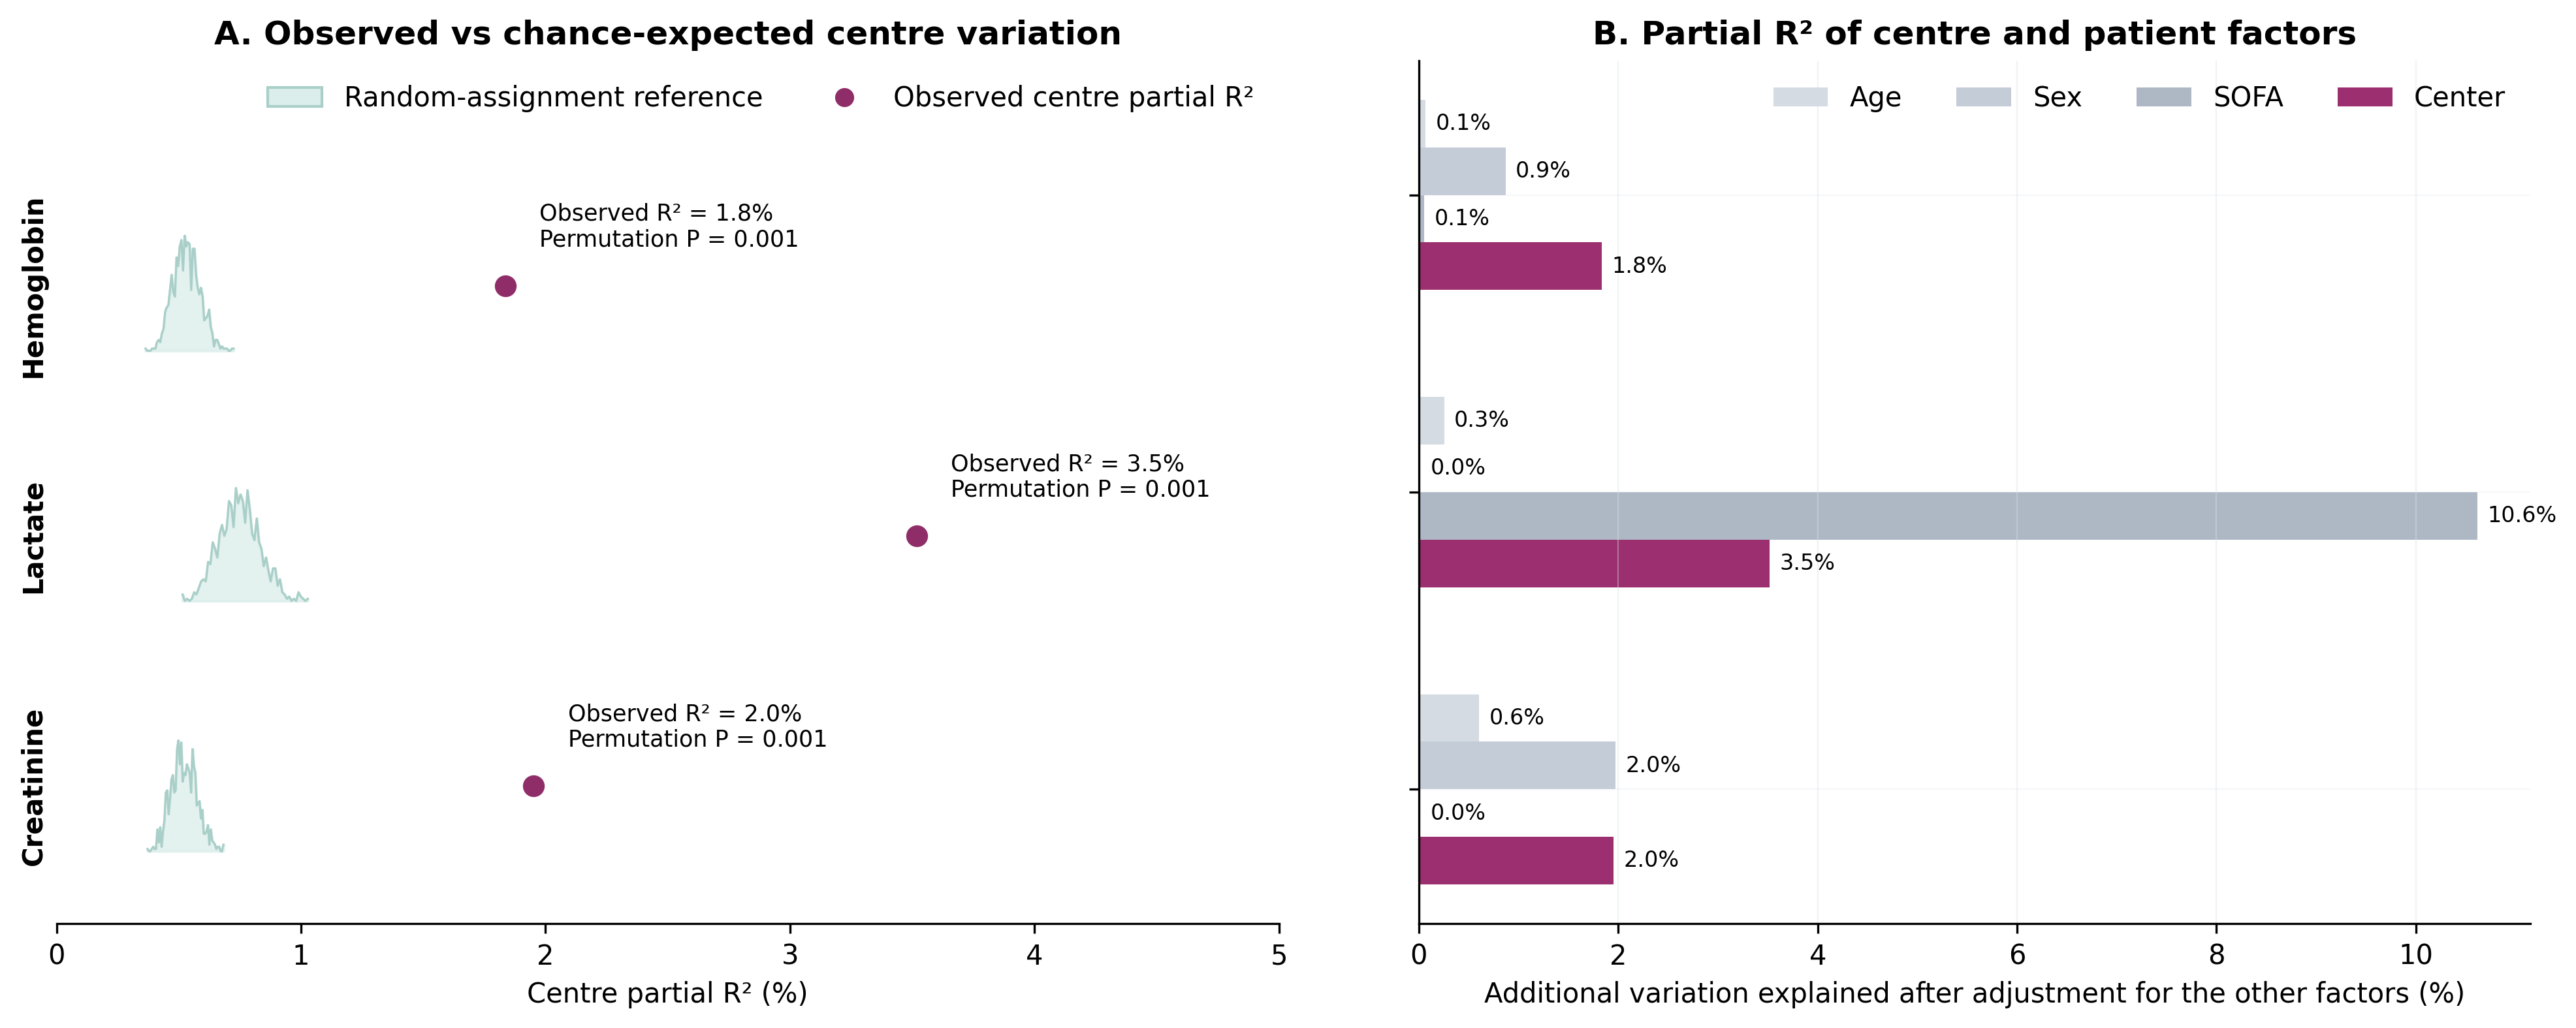

In [8]:
source_tables = RFBBP_RESULT

def residualize(y, x):
    design = np.column_stack([np.ones(len(x)), x])
    return y - design @ np.linalg.lstsq(design, y, rcond=None)[0]

def incremental_r2(y, target, adjust):
    reduced_residual = residualize(y, adjust)
    full_design = np.column_stack([adjust, target])
    full_residual = residualize(y, full_design)
    return 1 - np.sum(full_residual**2) / np.sum(reduced_residual**2)

partial_rows = []
permutation_rows = []
rng = np.random.default_rng(20260923)
N_PERMUTATIONS = 999

for variable, cohort in cohorts.items():
    label = BIOMARKERS[variable]["label"]
    sofa_col = "SOFA_no_renal_z" if variable == "Creatinine_hour_24" else "SOFA_score_hour_24_z"
    y = cohort.exposure_analysis.to_numpy(float)
    age = cohort.age_z.to_numpy(float)[:, None]
    sex = cohort.gender_male.to_numpy(float)[:, None]
    sofa = cohort[sofa_col].to_numpy(float)[:, None]
    centre = pd.get_dummies(cohort.center_id, drop_first=True, dtype=float).to_numpy()
    blocks = {"Age": age, "Sex": sex, "SOFA": sofa, "Center": centre}
    for predictor, target in blocks.items():
        other = [value for name, value in blocks.items() if name != predictor]
        value = incremental_r2(y, target, np.column_stack(other))
        partial_rows.append({"variable": variable, "biomarker_label": label,
                             "predictor": predictor, "partial_R2_percent": 100 * value,
                             "n": len(cohort), "centres": cohort.center_id.nunique()})

    # Use the same incremental partial-R² definition for Panel A and Panel B.
    # The cross-product calculation below is algebraically equivalent to
    # incremental_r2(y, centre_dummies, adjust), but avoids constructing a
    # large dummy matrix and refitting a patient-level model 1,000 times.
    adjust = np.column_stack([age, sex, sofa])
    reduced_design = np.column_stack([np.ones(len(y)), adjust])
    reduced_beta = np.linalg.lstsq(reduced_design, y, rcond=None)[0]
    reduced_residual = y - reduced_design @ reduced_beta
    reduced_sse = np.sum(reduced_residual**2)
    reduced_crossprod_inverse = np.linalg.pinv(reduced_design.T @ reduced_design)
    centre_codes, centre_levels = pd.factorize(cohort.center_id, sort=True)

    def center_partial_r2_from_codes(codes):
        n_centres = len(centre_levels)
        counts = np.bincount(codes, minlength=n_centres).astype(float)
        group_design = np.column_stack([
            np.bincount(codes, weights=reduced_design[:, column], minlength=n_centres)
            for column in range(reduced_design.shape[1])
        ])
        group_residual = np.bincount(codes, weights=reduced_residual, minlength=n_centres)
        # Match pd.get_dummies(..., drop_first=True) by omitting centre code 0.
        group_design = group_design[1:]
        score = group_residual[1:]
        information = (np.diag(counts[1:])
                       - group_design @ reduced_crossprod_inverse @ group_design.T)
        coefficient = np.linalg.lstsq(information, score, rcond=None)[0]
        explained_ss = float(score @ coefficient)
        return explained_ss / reduced_sse

    expected_center_r2 = next(row["partial_R2_percent"] for row in partial_rows
                              if row["variable"] == variable and row["predictor"] == "Center") / 100
    for permutation_id in range(N_PERMUTATIONS + 1):
        codes = centre_codes if permutation_id == 0 else rng.permutation(centre_codes)
        centre_r2 = center_partial_r2_from_codes(codes)
        if permutation_id == 0 and not np.isclose(centre_r2, expected_center_r2, rtol=1e-9, atol=1e-12):
            raise RuntimeError(f"Panel A/B center partial R² mismatch for {label}")
        permutation_rows.append({"variable": variable, "biomarker_label": label,
                                 "permutation": permutation_id, "center_R2_percent": 100 * centre_r2})

partial_r2 = pd.DataFrame(partial_rows)
permutation = pd.DataFrame(permutation_rows)
partial_r2.to_csv(TABLES / "pooled_covariate_partial_r2.csv", index=False)
permutation.to_csv(TABLES / "pooled_center_partial_r2_permutation_null.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.8), dpi=300, gridspec_kw={"width_ratios": [1.10, 1], "wspace": .12})
labels = ["Hemoglobin", "Lactate", "Creatinine"]
y_positions = np.arange(3)[::-1]
max_count = 1
histograms = []
for y, variable, label in zip(y_positions, BIOMARKERS, labels):
    null = permutation.loc[(permutation.variable.eq(variable)) & permutation.permutation.ne(0), "center_R2_percent"].to_numpy()
    counts, edges = np.histogram(null, bins=55)
    max_count = max(max_count, counts.max())
    histograms.append((y, variable, label, counts, edges))
for y, variable, label, counts, edges in histograms:
    observed = permutation.loc[(permutation.variable.eq(variable)) & permutation.permutation.eq(0), "center_R2_percent"].iloc[0]
    null = permutation.loc[(permutation.variable.eq(variable)) & permutation.permutation.ne(0), "center_R2_percent"]
    p_value = (1 + (null >= observed).sum()) / (len(null) + 1)
    mids = (edges[:-1] + edges[1:]) / 2
    baseline = y - .26
    scaled = counts / max_count * .46
    axes[0].fill_between(mids, baseline, baseline + scaled, color="#DCEEEB", alpha=.78)
    axes[0].plot(mids, baseline + scaled, color="#A9CFC8", lw=.8)
    axes[0].plot(observed, y, "o", color="#8F2D68", ms=7)
    axes[0].text(observed + .14, y + .14, f"Observed R² = {observed:.1f}%\nPermutation P {'< 0.001' if p_value < .001 else f'= {p_value:.3f}'}",
                 fontsize=8.4, va="bottom")
axes[0].set(yticks=y_positions, yticklabels=labels, xlabel="Centre partial R² (%)",
            title="A. Observed vs chance-expected centre variation", xlim=(0, 5), ylim=(-.55, 2.9))
for tick in axes[0].get_yticklabels():
    tick.set(fontweight="bold", rotation=90, va="center")
axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False)
axes[0].spines[["left", "top", "right"]].set_visible(False)
axes[0].tick_params(axis="y", length=0)
axes[0].legend(handles=[
    Patch(facecolor="#DCEEEB", edgecolor="#A9CFC8", label="Random-assignment reference"),
    plt.Line2D([0], [0], marker="o", linestyle="none", color="#8F2D68", label="Observed centre partial R²")],
    frameon=False, loc="upper right", ncol=2)

pivot = partial_r2.pivot(index="biomarker_label", columns="predictor", values="partial_R2_percent").reindex(["Hemoglobin", "Lactate", "Creatinine"])
y = np.arange(len(pivot))[::-1]; height = .16
for j, predictor in enumerate(["Age", "Sex", "SOFA", "Center"]):
    values = pivot[predictor].to_numpy()
    bars = axes[1].barh(y + (1.5-j)*height, values, height,
                 color="#9b2f6f" if predictor == "Center" else ["#d5dbe3", "#c4ccd7", "#aeb8c5"][j], label=predictor)
    for bar, value in zip(bars, values):
        axes[1].text(value + .1, bar.get_y()+bar.get_height()/2, f"{value:.1f}%", va="center", fontsize=8)
axes[1].set(yticks=y, yticklabels=[], xlabel="Additional variation explained after adjustment for the other factors (%)",
            title="B. Partial R² of centre and patient factors")
axes[1].legend(frameon=False, ncol=4, loc="upper right")
axes[1].grid(axis="x", color="#D9DEE7", linewidth=.55, alpha=.38)
axes[1].grid(axis="y", color="#D9DEE7", linewidth=.45, alpha=.28)
fig.subplots_adjust(left=.075, right=.99, top=.90, bottom=.14)
fig.savefig(FIGURES / "cross_centre_partial_r2_and_permutation.png", bbox_inches="tight"); plt.show()

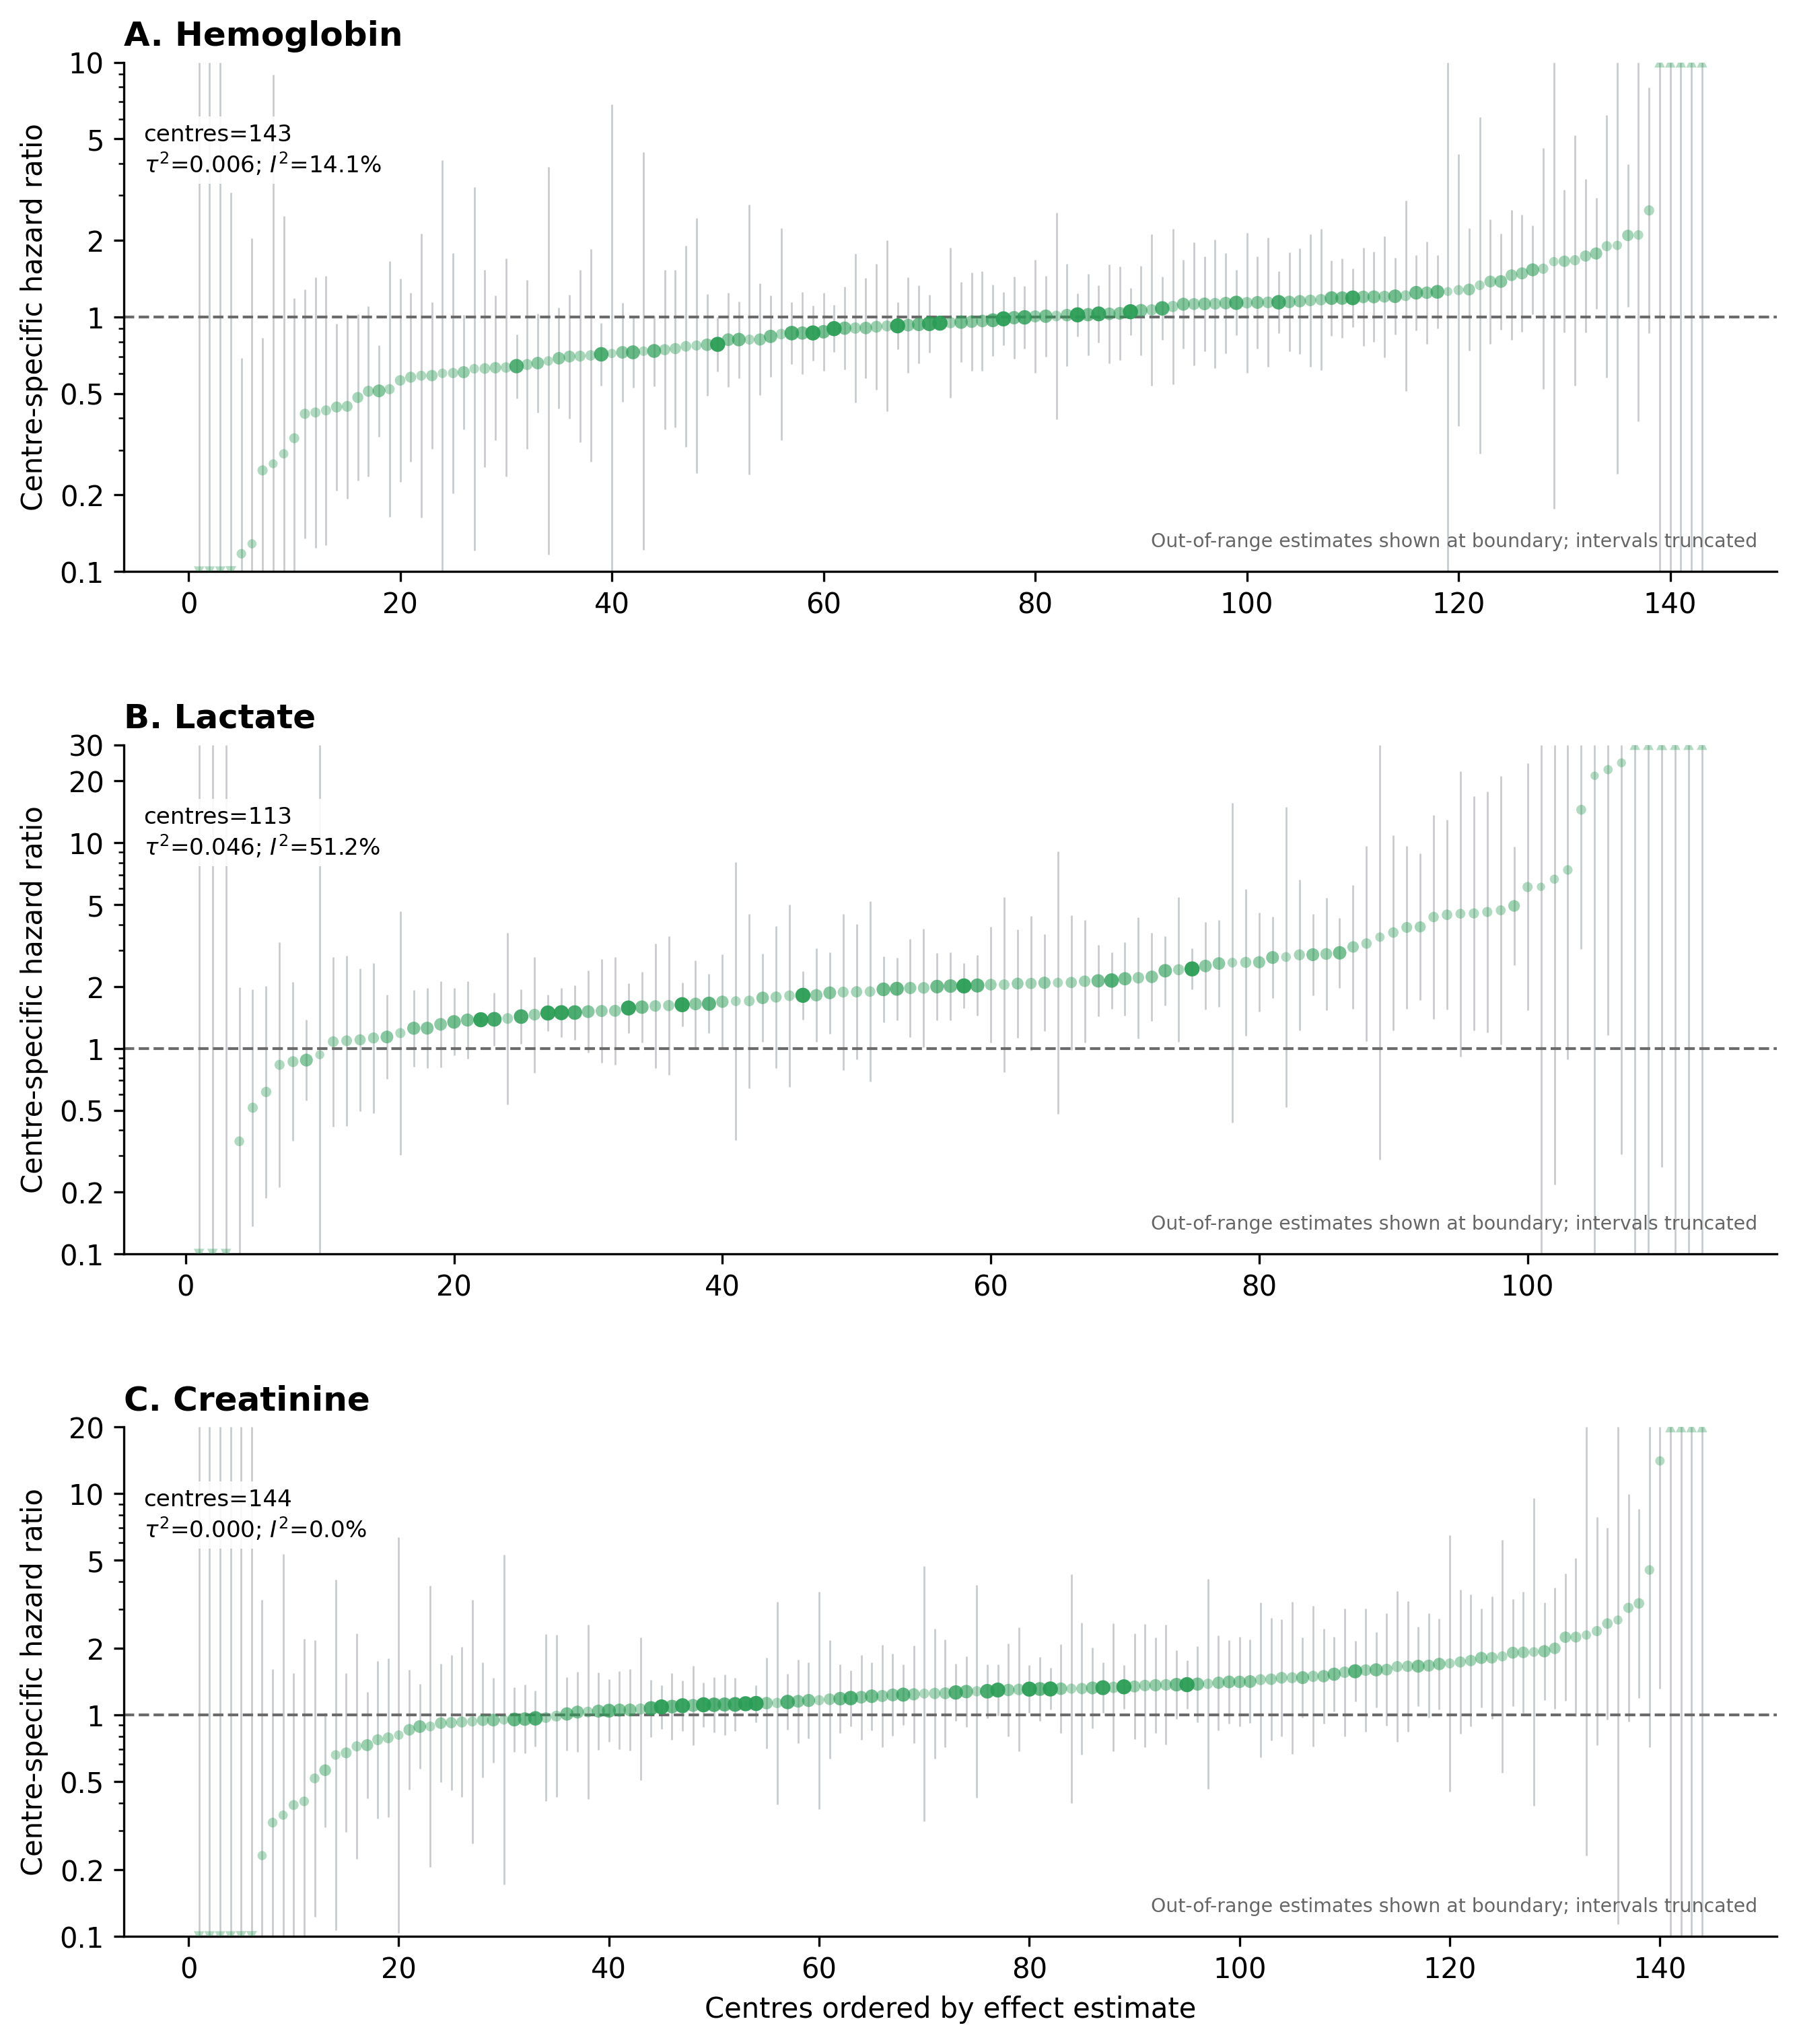

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(9.2, 10.2), dpi=300)
effect_axis_specs = {
    "Hemoglobin_hour_24": (0.10, 10.0, [0.1, 0.2, 0.5, 1, 2, 5, 10]),
    "Lactate_hour_24": (0.10, 30.0, [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 30]),
    "Creatinine_hour_24": (0.10, 20.0, [0.1, 0.2, 0.5, 1, 2, 5, 10, 20]),
}
for ax, (variable, spec) in zip(axes, BIOMARKERS.items()):
    centre_effects = pd.read_csv(TABLES / f"two_stage_centre_effects_{variable}.csv")
    # Use exactly the same estimability definition as the primary two-stage meta:
    # no n/event/nonevent threshold and no exclusion based on CI width.
    centre_effects = centre_effects.loc[
        centre_effects.status.eq("ok")
        & np.isfinite(centre_effects.coef)
        & np.isfinite(centre_effects.se)
        & centre_effects.se.gt(0)
    ].copy()
    centre_effects["hr"] = np.exp(np.clip(centre_effects.coef, -700, 700))
    centre_effects["ci_low"] = np.exp(np.clip(centre_effects.coef - 1.96 * centre_effects.se, -700, 700))
    centre_effects["ci_high"] = np.exp(np.clip(centre_effects.coef + 1.96 * centre_effects.se, -700, 700))
    display_low, display_high, display_ticks = effect_axis_specs[variable]
    centre_effects = centre_effects.sort_values("hr").reset_index(drop=True)
    x = np.arange(1, len(centre_effects) + 1)

    information = 1 / centre_effects.se.pow(2)
    info_low, info_high = information.quantile([0.05, 0.95])
    info_scaled = ((information - info_low) / max(info_high - info_low, np.finfo(float).eps)).clip(0, 1)
    point_sizes = 9 + 20 * np.sqrt(info_scaled)
    point_rgba = np.tile(np.array([42/255, 157/255, 85/255, 1.0]), (len(centre_effects), 1))
    point_rgba[:, 3] = 0.35 + 0.60 * info_scaled

    ax.vlines(x, centre_effects.ci_low.clip(display_low, display_high),
              centre_effects.ci_high.clip(display_low, display_high), color="#9aa0a6", lw=.65, alpha=.55)
    below = centre_effects.hr.lt(display_low)
    above = centre_effects.hr.gt(display_high)
    within = ~(below | above)
    ax.scatter(x[within], centre_effects.loc[within, "hr"], c=point_rgba[within],
               s=point_sizes[within], marker="o", edgecolors="none", zorder=3)
    ax.scatter(x[below], np.full(below.sum(), display_low), c=point_rgba[below],
               s=point_sizes[below] + 5, marker="v", edgecolors="none", zorder=3)
    ax.scatter(x[above], np.full(above.sum(), display_high), c=point_rgba[above],
               s=point_sizes[above] + 5, marker="^", edgecolors="none", zorder=3)
    ax.axhline(1, color="#6b6b6b", ls="--", lw=1)
    ax.set_yscale("log")
    ax.set_ylim(display_low, display_high)
    ax.set_yticks(display_ticks)
    ax.set_yticklabels([f"{value:g}" for value in display_ticks])
    ax.set_ylabel("Centre-specific hazard ratio")
    primary_meta = meta_results.loc[meta_results.variable.eq(variable)].iloc[0]
    tau2, i2 = float(primary_meta.tau2), float(primary_meta.I2)
    ax.set_title(f"{['A', 'B', 'C'][list(BIOMARKERS).index(variable)]}. {spec['label']}", loc="left", fontweight="bold")
    ax.text(.012, .88, f"centres={len(centre_effects)}\n$\\tau^2$={tau2:.3f}; $I^2$={i2:.1f}%",
            transform=ax.transAxes, va="top", fontsize=8.2,
            bbox={"facecolor": "white", "alpha": .88, "edgecolor": "none", "pad": 2.5})
    ax.text(.988, .04, "Out-of-range estimates shown at boundary; intervals truncated",
            transform=ax.transAxes,
            ha="right", va="bottom", fontsize=6.8, color="#666666")
    ax.grid(axis="y"); ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("Centres ordered by effect estimate")
fig.subplots_adjust(left=.095, right=.985, top=.975, bottom=.065, hspace=.34)
fig.savefig(FIGURES / "pooled_center_specific_cox_effects_three_biomarkers.png", bbox_inches="tight"); plt.show()

## 7. Latent-scale associations and attenuation consistency

In [10]:
# Main analysis plus five prior-sensitivity specifications for each biomarker.
# Long MCMC runs are opt-in; the command is sequential to avoid concurrent PyMC jobs.
import subprocess

RUN_PRIOR_SENSITIVITY_MCMC = False
REPOSITORY_ROOT = ROOT.parent

PRIOR_SENSITIVITY_BASH = r"""
mkdir -p case_multivar/analysis_final/logs/prior_sensitivity
bash case_multivar/run_rfbbp.sh sensitivity \
  > case_multivar/analysis_final/logs/prior_sensitivity/creatinine_sensitivity_ta095.log 2>&1
""".strip()

print(PRIOR_SENSITIVITY_BASH)
if RUN_PRIOR_SENSITIVITY_MCMC:
    subprocess.run(["bash", "-lc", PRIOR_SENSITIVITY_BASH], cwd=REPOSITORY_ROOT, check=True)

PRIOR_RESULT_DIR = RFBBP_RESULT / "prior_sensitivity"
PRIOR_TABLE_DIR = TABLES / "prior_sensitivity"
PRIOR_TABLE_DIR.mkdir(parents=True, exist_ok=True)

main_analysis_variables = {
    "Hemoglobin": "Hemoglobin_hour_24",
    "Lactate": "Lactate_hour_24",
    "Creatinine": "Creatinine_hour_24",
}
prior_scenarios = [
    ("Hemoglobin", "S1: More diffuse calibration priors", "hb_prior_S1_more_diffuse_calibration"),
    ("Hemoglobin", "S2: Stronger hierarchical shrinkage", "hb_prior_NS2_stronger_hier_shrinkage"),
    ("Hemoglobin", "S3: Weaker hierarchical shrinkage", "hb_prior_S3_weaker_hier_shrinkage"),
    ("Hemoglobin", "S4: Alternative measurement-variability prior", "hb_prior_S4_hn_sigmaw1"),
    ("Hemoglobin", "S5: More concentrated exposure-effect prior", "hb_prior_NS4_betax_sigma1"),
    ("Lactate", "S1: More diffuse calibration priors", "lactate_prior_S1_more_diffuse_calibration_rerun"),
    ("Lactate", "S2: Stronger hierarchical shrinkage", "lactate_prior_NS2_stronger_hier_shrinkage"),
    ("Lactate", "S3: Weaker hierarchical shrinkage", "lactate_prior_S3_weaker_hier_shrinkage"),
    ("Lactate", "S4: Alternative measurement-variability prior", "lactate_prior_S4_hn_sigmaw1"),
    ("Lactate", "S5: More concentrated exposure-effect prior", "lactate_prior_NS4_betax_sigma1"),
    ("Creatinine", "S1: More diffuse calibration priors", "creatinine_prior_S1_more_diffuse_calibration"),
    ("Creatinine", "S2: Stronger hierarchical shrinkage", "creatinine_prior_NS2_stronger_hier_shrinkage"),
    ("Creatinine", "S3: Weaker hierarchical shrinkage", "creatinine_prior_S3_weaker_hier_shrinkage"),
    ("Creatinine", "S4: Alternative measurement-variability prior", "creatinine_prior_S4_hn_sigmaw1"),
    ("Creatinine", "S5: More concentrated exposure-effect prior", "creatinine_prior_NS4_betax_sigma1"),
]


def require_one(directory, pattern, label):
    matches = sorted(directory.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {label} in {directory} matching {pattern!r}; found {matches}"
        )
    return matches[0]


def read_diagnostic_series(path):
    diagnostics = pd.read_csv(path, index_col=0)
    return diagnostics.iloc[:, 0] if diagnostics.shape[1] == 1 else diagnostics.iloc[0]


def posterior_effect_row(biomarker, analysis, summary_path, diagnostics_path=None):
    posterior = pd.read_csv(summary_path, index_col=0)
    missing = [name for name in ["beta_x", "HR_x"] if name not in posterior.index]
    if missing:
        raise KeyError(f"{summary_path} is missing posterior rows: {missing}")
    beta_x = posterior.loc["beta_x"]
    hr_x = posterior.loc["HR_x"]
    row = {
        "Biomarker": biomarker,
        "analysis": analysis,
        "β_x": float(beta_x["estimate"]),
        "HR": float(hr_x["estimate"]),
        "HR_95%CrI": f"{hr_x['CI_1']:.3f}–{hr_x['CI_2']:.3f}",
        "beta_x_r_hat": float(beta_x.get("r_hat", np.nan)),
        "beta_x_ess_bulk": float(beta_x.get("ess_bulk", np.nan)),
        "divergences": np.nan,
    }
    if diagnostics_path is not None:
        diagnostics = read_diagnostic_series(diagnostics_path)
        row.update({
            "beta_x_r_hat": float(diagnostics["diag_beta_x_r_hat"]),
            "beta_x_ess_bulk": float(diagnostics["diag_beta_x_ess_bulk"]),
            "divergences": int(diagnostics["diag_n_divergent"]),
        })
    return row


# Six model specifications per biomarker: main analysis followed by S1-S5.
analysis_rows = []
for biomarker, variable in main_analysis_variables.items():
    main_summary = RFBBP_RESULT / (
        f"{variable}_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_"
        "5interval_no_center_filter_mimic_eicu_summary.csv"
    )
    if not main_summary.exists():
        raise FileNotFoundError(f"Missing main-analysis posterior summary: {main_summary}")
    analysis_rows.append(posterior_effect_row(biomarker, "Main analysis", main_summary))

    for sensitivity_biomarker, analysis, tag in prior_scenarios:
        if sensitivity_biomarker != biomarker:
            continue
        summary_path = require_one(PRIOR_RESULT_DIR, f"*_{tag}_summary.csv", f"summary for {tag}")
        diagnostics_path = require_one(
            PRIOR_RESULT_DIR, f"*_{tag}_diagnostics.csv", f"diagnostics for {tag}"
        )
        analysis_rows.append(
            posterior_effect_row(biomarker, analysis, summary_path, diagnostics_path)
        )

main_and_sensitivity_audit = pd.DataFrame(analysis_rows)
if len(main_and_sensitivity_audit) != 18:
    raise RuntimeError(f"Expected 18 model rows (3 biomarkers × 6 analyses); found {len(main_and_sensitivity_audit)}")

sensitivity_only = main_and_sensitivity_audit.loc[
    main_and_sensitivity_audit["analysis"].ne("Main analysis")
]
if sensitivity_only["divergences"].gt(0).any() or sensitivity_only["beta_x_r_hat"].gt(1.01).any():
    raise RuntimeError("At least one selected prior-sensitivity fit failed the convergence gate.")

main_and_sensitivity_table = main_and_sensitivity_audit[
    ["Biomarker", "analysis", "β_x", "HR", "HR_95%CrI"]
].copy()
main_and_sensitivity_table[["β_x", "HR"]] = main_and_sensitivity_table[["β_x", "HR"]].round(3)
effect_csv = PRIOR_TABLE_DIR / "rfbbp_main_and_prior_sensitivity_effect_summary.csv"
effect_xlsx = PRIOR_TABLE_DIR / "rfbbp_main_and_prior_sensitivity_effect_summary.xlsx"
main_and_sensitivity_table.to_csv(effect_csv, index=False)
main_and_sensitivity_table.to_excel(effect_xlsx, index=False)
display(main_and_sensitivity_table)


mkdir -p case_multivar/analysis_final/logs/prior_sensitivity
bash case_multivar/run_rfbbp.sh sensitivity \
  > case_multivar/analysis_final/logs/prior_sensitivity/creatinine_sensitivity_ta095.log 2>&1


,Biomarker,analysis,β_x,HR,HR_95%CrI
0,Hemoglobin,Main analysis,-0.050,0.951,0.927–0.975
1,Hemoglobin,S1: More diffuse calibration priors,-0.050,0.951,0.926–0.975
2,Hemoglobin,S2: Stronger hierarchical shrinkage,-0.050,0.951,0.926–0.975
3,Hemoglobin,S3: Weaker hierarchical shrinkage,-0.050,0.951,0.926–0.975
4,Hemoglobin,S4: Alternative measurement-variability prior,-0.051,0.950,0.924–0.975
5,Hemoglobin,S5: More concentrated exposure-effect prior,-0.050,0.951,0.927–0.976
6,Lactate,Main analysis,0.937,2.554,2.379–2.755
7,Lactate,S1: More diffuse calibration priors,0.936,2.553,2.363–2.737
8,Lactate,S2: Stronger hierarchical shrinkage,0.938,2.556,2.377–2.750
9,Lactate,S3: Weaker hierarchical shrinkage,0.939,2.559,2.372–2.747


### 7.1 RFBBP convergence diagnostics for the main and prior-sensitivity analyses

The table contains six model specifications per biomarker (main analysis and S1–S5). Main-analysis diagnostics are retained in the `analysis_final/tables` snapshot; every sensitivity row is rebuilt from the matching diagnostics and metadata files under `analysis_final/RFBBP_result/prior_sensitivity`. No `analysis_simple` files are read.

In [11]:
# Manuscript-ready MCMC diagnostic table: main analysis plus S1-S5.
# Inputs are restricted to analysis_final/RFBBP_result and analysis_final/tables.
import json

MAIN_DIAGNOSTIC_SNAPSHOT = TABLES / "rfbbp_main_and_prior_sensitivity_diagnostics.csv"


def diagnostic_table_row(indicator, analysis, diagnostics_path, metadata_path):
    diagnostics = read_diagnostic_series(diagnostics_path)
    with open(metadata_path, encoding="utf-8") as stream:
        metadata = json.load(stream)
    sampling = metadata["model_kwargs"]
    return {
        "Indicator": indicator,
        "analysis": analysis,
        "n": int(diagnostics["diag_n"]),
        "events": int(diagnostics["diag_n_events"]),
        "centers": int(diagnostics["diag_n_studies"]),
        "draws": int(sampling["draws"]),
        "tune": int(sampling["tune"]),
        "chains": int(sampling["chains"]),
        "target_accept": float(sampling["target_accept"]),
        "maximum Rhat": float(diagnostics["diag_max_r_hat"]),
        "minimum bulk ESS": int(diagnostics["diag_min_ess_bulk"]),
        "minimum tail ESS": int(diagnostics["diag_min_ess_tail"]),
        "beta_x Rhat": float(diagnostics["diag_beta_x_r_hat"]),
        "beta_x bulk ESS": int(diagnostics["diag_beta_x_ess_bulk"]),
        "divergences": int(diagnostics["diag_n_divergent"]),
        "minimum BFMI": float(diagnostics["diag_min_bfmi"]),
    }


# The three main-analysis diagnostic rows are retained in the analysis_final snapshot.
# Every S1-S5 row is rebuilt from its own diagnostics and metadata in RFBBP_result.
if not MAIN_DIAGNOSTIC_SNAPSHOT.exists():
    raise FileNotFoundError(f"Missing main-analysis diagnostic snapshot: {MAIN_DIAGNOSTIC_SNAPSHOT}")
main_snapshot = pd.read_csv(MAIN_DIAGNOSTIC_SNAPSHOT)
main_rows = main_snapshot.loc[main_snapshot["analysis"].eq("Main analysis")].copy()
if len(main_rows) != 3 or set(main_rows["Indicator"]) != set(main_analysis_variables):
    raise RuntimeError(
        "The main-analysis diagnostic snapshot must contain exactly one Main analysis row "
        "for Hemoglobin, Lactate, and Creatinine."
    )

diagnostic_rows = []
for indicator in main_analysis_variables:
    diagnostic_rows.append(main_rows.loc[main_rows["Indicator"].eq(indicator)].iloc[0].to_dict())
    for sensitivity_indicator, analysis, tag in prior_scenarios:
        if sensitivity_indicator != indicator:
            continue
        diagnostics_path = require_one(
            PRIOR_RESULT_DIR, f"*_{tag}_diagnostics.csv", f"diagnostics for {tag}"
        )
        metadata_path = require_one(
            PRIOR_RESULT_DIR, f"*_{tag}_metadata.json", f"metadata for {tag}"
        )
        diagnostic_rows.append(
            diagnostic_table_row(indicator, analysis, diagnostics_path, metadata_path)
        )

diagnostic_columns = [
    "Indicator", "analysis", "n", "events", "centers", "draws", "tune",
    "chains", "target_accept", "maximum Rhat", "minimum bulk ESS",
    "minimum tail ESS", "beta_x Rhat", "beta_x bulk ESS", "divergences",
    "minimum BFMI",
]
rfbbp_diagnostic_table = pd.DataFrame(diagnostic_rows, columns=diagnostic_columns)
if len(rfbbp_diagnostic_table) != 18:
    raise RuntimeError(f"Expected 18 diagnostic rows (3 biomarkers × 6 analyses); found {len(rfbbp_diagnostic_table)}")
if rfbbp_diagnostic_table.duplicated(["Indicator", "analysis"]).any():
    duplicates = rfbbp_diagnostic_table.loc[
        rfbbp_diagnostic_table.duplicated(["Indicator", "analysis"], keep=False),
        ["Indicator", "analysis"],
    ]
    raise RuntimeError(f"Duplicate diagnostic rows detected:\n{duplicates}")

for column in ["maximum Rhat", "beta_x Rhat", "minimum BFMI"]:
    rfbbp_diagnostic_table[column] = rfbbp_diagnostic_table[column].round(2)
rfbbp_diagnostic_table["target_accept"] = rfbbp_diagnostic_table["target_accept"].round(2)

diagnostic_csv = TABLES / "rfbbp_main_and_prior_sensitivity_diagnostics.csv"
diagnostic_xlsx = TABLES / "rfbbp_main_and_prior_sensitivity_diagnostics.xlsx"
rfbbp_diagnostic_table.to_csv(diagnostic_csv, index=False)
rfbbp_diagnostic_table.to_excel(diagnostic_xlsx, index=False)
display(rfbbp_diagnostic_table)


,Indicator,analysis,n,events,centers,draws,tune,chains,target_accept,maximum Rhat,minimum bulk ESS,minimum tail ESS,beta_x Rhat,beta_x bulk ESS,divergences,minimum BFMI
0,Hemoglobin,Main analysis,34870,6322,186,2000,2000,4,0.95,1.00,2913,3915,1.00,11973,0,0.92
1,Hemoglobin,S1: More diffuse calibration priors,34870,6322,186,2000,2000,4,0.95,1.00,2831,4152,1.00,11290,0,0.90
2,Hemoglobin,S2: Stronger hierarchical shrinkage,34870,6322,186,2000,2000,4,0.95,1.00,2839,4088,1.00,10530,0,0.89
3,Hemoglobin,S3: Weaker hierarchical shrinkage,34870,6322,186,2000,2000,4,0.95,1.00,2460,4004,1.00,9802,0,0.87
4,Hemoglobin,S4: Alternative measurement-variability prior,34870,6322,186,2000,2000,4,0.95,1.01,802,305,1.00,9448,0,0.93
5,Hemoglobin,S5: More concentrated exposure-effect prior,34870,6322,186,2000,2000,4,0.95,1.00,2833,3924,1.00,12072,0,0.90
6,Lactate,Main analysis,22708,5043,171,2000,2000,4,0.95,1.00,1101,2370,1.00,1101,0,0.59
7,Lactate,S1: More diffuse calibration priors,22708,5043,171,2000,3000,4,0.98,1.00,1402,2617,1.00,1402,0,0.62
8,Lactate,S2: Stronger hierarchical shrinkage,22708,5043,171,2000,2000,4,0.95,1.00,1053,1550,1.00,1053,0,0.62
9,Lactate,S3: Weaker hierarchical shrinkage,22708,5043,171,2000,2000,4,0.95,1.00,1209,2611,1.00,1209,0,0.63


In [12]:
rfbbp_rows = []
rfbbp_dir = RFBBP_RESULT
for variable, spec in BIOMARKERS.items():
    path = rfbbp_dir / f"{variable}_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_no_center_filter_mimic_eicu_summary.csv"
    summary = pd.read_csv(path, index_col=0)
    estimate = summary.loc["HR_x"]
    rfbbp_rows.append({"variable": variable, "indicator": spec["label"], "method": "RFBBP",
                       "hr": estimate.estimate, "ci_low": estimate.CI_1, "ci_high": estimate.CI_2,
                       "log_hr": np.log(estimate.estimate)})
rfbbp_results = pd.DataFrame(rfbbp_rows)

four_methods = pd.concat([
    cox_results[["variable", "indicator", "method", "hr", "ci_low", "ci_high", "log_hr"]],
    meta_results.assign(method="Two-stage meta")[["variable", "indicator", "method", "hr", "ci_low", "ci_high", "coef"]]
        .rename(columns={"coef": "log_hr"}),
    rfbbp_results,
], ignore_index=True)
four_methods["effect_95ci"] = four_methods.apply(lambda r: f"{r.hr:.3f} ({r.ci_low:.3f}, {r.ci_high:.3f})", axis=1)
four_method_table = four_methods.pivot(index="indicator", columns="method", values="effect_95ci")
four_method_table = four_method_table.reindex(index=["Hemoglobin", "Lactate", "Creatinine"], columns=["Naive", "Naive_std", "Two-stage meta", "RFBBP"])
four_methods.to_csv(TABLES / "four_method_effects_three_biomarkers.csv", index=False)
four_method_table.to_csv(TABLES / "four_method_effects_article_table.csv")
display(four_method_table)

method,Naive,Naive_std,Two-stage meta,RFBBP
indicator,,,,
Hemoglobin,"0.976 (0.964, 0.987)","0.948 (0.925, 0.972)","0.957 (0.918, 0.997)","0.951 (0.927, 0.975)"
Lactate,"1.873 (1.799, 1.950)","1.524 (1.483, 1.567)","1.854 (1.724, 1.994)","2.554 (2.379, 2.755)"
Creatinine,"1.221 (1.181, 1.264)","1.163 (1.134, 1.193)","1.171 (1.141, 1.202)","1.453 (1.338, 1.585)"


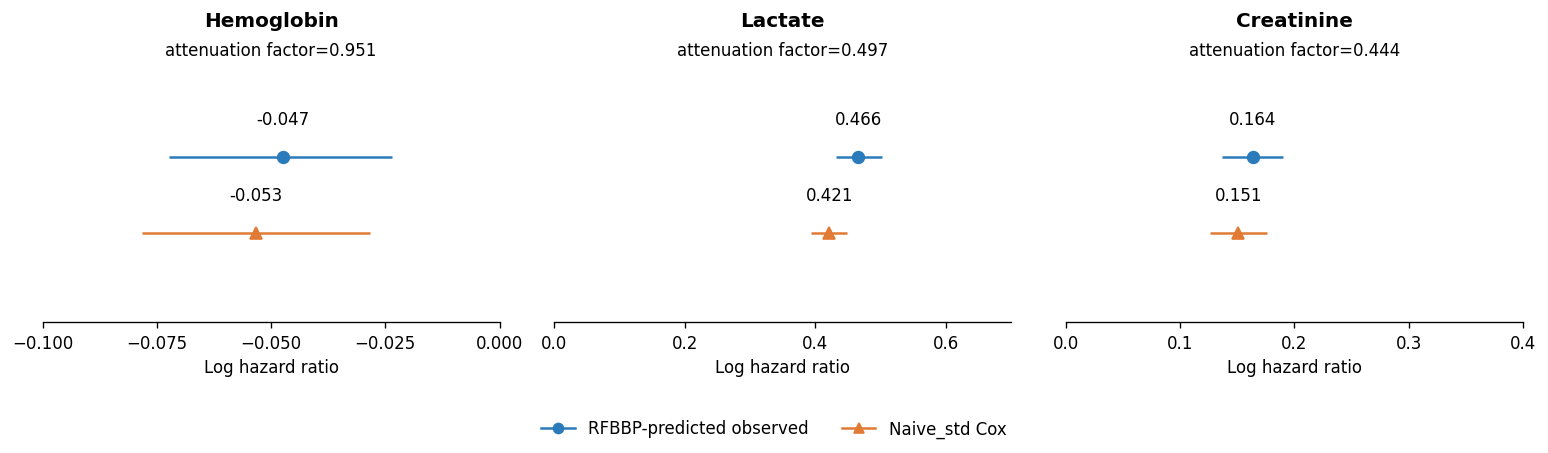

In [13]:
def posterior_array(data_array, value_dim=None):
    stacked = data_array.stack(sample=("chain", "draw"))
    if value_dim is not None:
        stacked = stacked.transpose("sample", value_dim)
    return np.asarray(stacked.values)


def draw_summary(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    median, low, high = np.quantile(values, [0.50, 0.025, 0.975])
    return float(median), float(low), float(high)


attenuation_benchmark_rows = []
attenuation_rows = []

for biomarker_index, (variable, spec) in enumerate(BIOMARKERS.items()):
    # These centre parameters and posterior draws are RFBBP model outputs. All
    # traditional-model estimates and weights below are generated in this notebook.
    parameters = pd.read_csv(source_tables / f"rfbbp_absigma_center_parameters_{variable}_linear.csv")
    parameters = parameters.loc[
        parameters.database_group.eq("mimic+eicu")
        & parameters.center_filter_label.eq("no_filter")
    ].copy()
    posterior_path = Path(parameters.netcdf.iloc[0])
    if not posterior_path.exists():
        raise FileNotFoundError(f"Missing RFBBP posterior: {posterior_path}")

    point_parameters = parameters.pivot(index="idx", columns="parameter", values="estimate")
    point_parameters = point_parameters.dropna(subset=["b", "sigma_w"]).reset_index()
    center_ids = np.unique(cohorts[variable].center_id.astype(str).to_numpy())
    point_parameters["center_id"] = point_parameters["idx"].astype(int).map(
        lambda idx: center_ids[idx]
    )
    point_parameters["rho"] = point_parameters.b.pow(2) / (
        point_parameters.b.pow(2) + point_parameters.sigma_w.pow(2)
    )

    center_effects = two_stage_center_results_by_variable[variable].copy()
    center_effects["center_id"] = center_effects.center_id.astype(str)
    center_effects["information_weight"] = np.where(
        center_effects.status.eq("ok")
        & np.isfinite(center_effects.se)
        & center_effects.se.gt(0),
        1.0 / np.square(center_effects.se.astype(float)),
        np.nan,
    )
    weighted_centers = point_parameters.merge(
        center_effects[["center_id", "information_weight"]], on="center_id", how="left"
    )
    weighted_centers = weighted_centers.loc[
        weighted_centers.information_weight.notna()
        & weighted_centers.information_weight.gt(0)
    ].copy()
    center_index = weighted_centers.idx.astype(int).to_numpy()
    weights = weighted_centers.information_weight.astype(float).to_numpy()

    with xr.open_dataset(posterior_path, group="posterior") as posterior:
        b_dim = next(dim for dim in posterior["b"].dims if dim not in {"chain", "draw"})
        sigma_dim = next(dim for dim in posterior["sigma_w"].dims if dim not in {"chain", "draw"})
        b_draws = posterior_array(posterior["b"], b_dim)[:, center_index]
        sigma_draws = posterior_array(posterior["sigma_w"], sigma_dim)[:, center_index]
        beta_rfbbp_draws = posterior_array(posterior["beta_x"]).reshape(-1)

    rho_draws = np.square(b_draws) / (np.square(b_draws) + np.square(sigma_draws))
    attenuation_draws = np.sum(np.sqrt(rho_draws) * weights[None, :], axis=1) / weights.sum()
    predicted_draws = beta_rfbbp_draws * attenuation_draws

    naive = cox_results.loc[
        cox_results.variable.eq(variable) & cox_results.method.eq("Naive_std")
    ].iloc[0]
    rng = np.random.default_rng(20260901 + biomarker_index)
    naive_draws = rng.normal(float(naive.log_hr), float(naive.se), len(attenuation_draws))
    expected_latent_draws = naive_draws / attenuation_draws

    attenuation_factor, attenuation_low, attenuation_high = draw_summary(attenuation_draws)
    predicted_beta, predicted_low, predicted_high = draw_summary(predicted_draws)
    rfbbp_beta, rfbbp_low, rfbbp_high = draw_summary(beta_rfbbp_draws)
    expected_beta, expected_low, expected_high = draw_summary(expected_latent_draws)
    common = {
        "variable": variable,
        "indicator": spec["label"],
        "database_group": "mimic+eicu",
        "database_label": "MIMIC-IV + eICU",
        "rho_median": float(point_parameters.rho.median()),
        "attenuation_factor": attenuation_factor,
        "attenuation_ci_low": attenuation_low,
        "attenuation_ci_high": attenuation_high,
        "n_centers_weighted": int(len(weighted_centers)),
        "n": int(naive.n),
        "events": int(naive.events),
    }
    attenuation_benchmark_rows.extend([
        {**common, "comparison": "latent_scale", "method": "Expected corrected beta_x",
         "beta": expected_beta, "ci_low": expected_low, "ci_high": expected_high},
        {**common, "comparison": "latent_scale", "method": "Observed RFBBP beta_x",
         "beta": rfbbp_beta, "ci_low": rfbbp_low, "ci_high": rfbbp_high},
        {**common, "comparison": "observed_scale", "method": "Predicted observed beta",
         "beta": predicted_beta, "ci_low": predicted_low, "ci_high": predicted_high},
        {**common, "comparison": "observed_scale", "method": "Naive_std beta",
         "beta": float(naive.log_hr), "ci_low": float(np.log(naive.ci_low)),
         "ci_high": float(np.log(naive.ci_high))},
    ])
    attenuation_rows.extend([
        {"variable": variable, "indicator": spec["label"], "method": "RFBBP projection",
         "log_hr": predicted_beta, "ci_low": predicted_low, "ci_high": predicted_high,
         "rho_median": common["rho_median"], "attenuation_factor": attenuation_factor},
        {"variable": variable, "indicator": spec["label"], "method": "Naive_std Cox",
         "log_hr": float(naive.log_hr), "ci_low": float(np.log(naive.ci_low)),
         "ci_high": float(np.log(naive.ci_high)), "rho_median": common["rho_median"],
         "attenuation_factor": attenuation_factor},
    ])

attenuation_benchmark = pd.DataFrame(attenuation_benchmark_rows)
attenuation_benchmark.to_csv(TABLES / "attenuation_benchmarks_generated.csv", index=False)
attenuation = pd.DataFrame(attenuation_rows)
attenuation.to_csv(TABLES / "attenuation_naive_std_rfbbp.csv", index=False)

attenuation_x_limits = {
    "Hemoglobin": (-0.10, 0.00),
    "Lactate": (0.00, 0.70),
    "Creatinine": (0.00, 0.40),
}
attenuation_x_ticks = {
    "Hemoglobin": [-0.10, -0.075, -0.05, -0.025, 0.00],
    "Lactate": [0.00, 0.20, 0.40, 0.60],
    "Creatinine": [0.00, 0.10, 0.20, 0.30, 0.40],
}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, label in zip(axes, ["Hemoglobin", "Lactate", "Creatinine"]):
    panel = attenuation.loc[attenuation.indicator.eq(label)]
    for y, (method, color, marker) in zip([0.56, 0.44], [("RFBBP projection", COLORS["rfbbp"], "o"), ("Naive_std Cox", COLORS["naive"], "^")]):
        row = panel.loc[panel.method.eq(method)].iloc[0]
        ax.errorbar(row.log_hr, y, xerr=[[row.log_hr-row.ci_low], [row.ci_high-row.log_hr]], fmt=marker, color=color, capsize=0, ms=7)
        ax.text(row.log_hr, y+.045, f"{row.log_hr:.3f}", ha="center", va="bottom")
    factor = panel.attenuation_factor.iloc[0]
    ax.set_xlim(*attenuation_x_limits[label])
    ax.set_xticks(attenuation_x_ticks[label])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", left=False)
    ax.set(yticks=[], ylim=(0.30, 0.70), xlabel="Log hazard ratio")
    ax.set_title(label, fontweight="bold", pad=25)
    ax.text(0.5, 1.035, f"attenuation factor={factor:.3f}", transform=ax.transAxes,
            ha="center", va="bottom", fontweight="normal")
legend_handles = [
    plt.Line2D([0], [0], color=COLORS["rfbbp"], marker="o", linestyle="-",
               label="RFBBP-predicted observed"),
    plt.Line2D([0], [0], color=COLORS["naive"], marker="^", linestyle="-",
               label="Naive_std Cox"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, .12, 1, 1)); fig.savefig(FIGURES / "attenuation_three_biomarkers.png", bbox_inches="tight"); plt.show()

## 8. Centre-specific equivalent thresholds and held-out consequences

For a fixed clinical reference (c), the common latent reference state is

\[
x_c=\operatorname{median}_s\{[g(c)-a_s]/b_s\},
\]

and the centre-specific equivalent threshold is (c_s=g^{-1}(a_s+b_sx_c)). Panel C requires centre (n\ge20), events and non-events \(\ge5\), both threshold groups \(\ge5\), at least one event in each group, and finite coefficient and SE. Uniform and RFBBP meta-analyses use the same intersection of estimable centres and the same DerSimonian–Laird method.

In [14]:
THRESHOLDS = {"Hemoglobin_hour_24": [8.0, 12.0], "Lactate_hour_24": [4.0, 8.0], "Creatinine_hour_24": [2.0]}
MAIN_THRESHOLDS = {"Hemoglobin_hour_24": 8.0, "Lactate_hour_24": 4.0, "Creatinine_hour_24": 2.0}

threshold_rows = []
threshold_details = []
reclassification_details = []
validation_sets = {}
threshold_maps = {}
saved_split = pd.read_csv(source_tables / "three_biomarkers_train70_validate30_rfbbp_threshold_transportability_split_assignment.csv")
split_audit_rows = []
for variable, values in THRESHOLDS.items():
    slug = BIOMARKERS[variable]["label"].lower()
    params = pd.read_csv(source_tables / f"{slug}_train70_validate30_rfbbp_threshold_transportability_training_calibration_parameters.csv")
    cohort = cohorts[variable].copy()
    assignment = saved_split.loc[saved_split.biomarker.eq(BIOMARKERS[variable]["label"])].reset_index(drop=True)
    original = pd.read_csv(RFBBP_RESULT / f"{variable}_sofa_adjusted.csv")
    original_ordered = pd.concat([group for _, group in original.groupby("center_id", sort=False)], ignore_index=True)
    same_rows = (len(original_ordered) == len(assignment) and
                 original_ordered.database.astype(str).equals(assignment.database.astype(str)) and
                 original_ordered.center_id.astype(str).equals(assignment.center_id.astype(str)) and
                 np.array_equal(original_ordered.event.to_numpy(), assignment.event.to_numpy()) and
                 np.allclose(original_ordered.time, assignment.time, rtol=0, atol=1e-10) and
                 np.allclose(original_ordered.exposure_analysis, assignment.exposure_analysis, rtol=0, atol=1e-10))
    if not same_rows:
        raise ValueError(f"Saved split rows do not align with the original {variable} analysis dataset")
    split_by_stay = original_ordered[["database", "stay_id"]].copy()
    split_by_stay["split"] = assignment.split.to_numpy()
    cohort = cohort.merge(split_by_stay, on=["database", "stay_id"], how="left", validate="one_to_one")
    matched_n = int(cohort.split.notna().sum())
    split_audit_rows.append({"variable": variable, "cohort_n": len(cohort), "assignment_n": len(assignment),
                             "saved_rows_aligned": same_rows, "matched_n": matched_n,
                             "validation_n": int(cohort.split.eq("validation").sum())})
    if matched_n != len(cohort) or len(assignment) != len(cohort):
        raise ValueError(f"Saved split does not match the {variable} analysis cohort one-to-one")
    validation = cohort.loc[cohort.split.eq("validation")].merge(params[["center_id", "a", "b", "sigma_w"]], on="center_id", how="inner")
    validation_sets[variable] = validation

    for reference_value in values:
        reference_analysis = np.log(reference_value) if BIOMARKERS[variable]["scale"] == "log" else reference_value
        latent_states = (reference_analysis - params.a) / params.b
        common_state = float(latent_states.median())
        centre_threshold_analysis = params.a + params.b * common_state
        centre_threshold_raw = np.exp(centre_threshold_analysis) if BIOMARKERS[variable]["scale"] == "log" else centre_threshold_analysis
        centre_thresholds = params[["center_id", "database"]].copy()
        centre_thresholds["equivalent_threshold"] = centre_threshold_raw
        centre_thresholds["reference_value"] = reference_value
        centre_thresholds["variable"] = variable
        threshold_details.append(centre_thresholds)
        threshold_maps[(variable, reference_value)] = centre_thresholds.set_index("center_id")["equivalent_threshold"]

        assessed = validation.merge(centre_thresholds[["center_id", "equivalent_threshold"]], on="center_id", how="inner")
        low_is_abnormal = variable == "Hemoglobin_hour_24"
        uniform_flag = assessed.exposure_raw.le(reference_value) if low_is_abnormal else assessed.exposure_raw.ge(reference_value)
        calibrated_flag = assessed.exposure_raw.le(assessed.equivalent_threshold) if low_is_abnormal else assessed.exposure_raw.ge(assessed.equivalent_threshold)
        assessed["reclassified"] = uniform_flag.ne(calibrated_flag)
        by_centre = assessed.groupby(["database", "center_id"]).reclassified.agg(["size", "sum", "mean"]).reset_index()
        by_centre["variable"] = variable
        by_centre["reference_value"] = reference_value
        by_centre["reclassified_percent"] = 100 * by_centre["mean"]
        reclassification_details.append(by_centre)
        threshold_rows.append({"variable": variable, "biomarker": BIOMARKERS[variable]["label"],
                               "reference_value": reference_value, "unit": BIOMARKERS[variable]["unit"],
                               "equivalent_min": centre_threshold_raw.min(), "equivalent_p25": centre_threshold_raw.quantile(.25),
                               "equivalent_median": centre_threshold_raw.median(), "equivalent_p75": centre_threshold_raw.quantile(.75),
                               "equivalent_max": centre_threshold_raw.max(), "validation_n": len(assessed),
                               "reclassified_n": int(assessed.reclassified.sum()),
                               "reclassified_percent": 100 * assessed.reclassified.mean()})

threshold_summary = pd.DataFrame(threshold_rows)
centre_equivalent_thresholds = pd.concat(threshold_details, ignore_index=True)
reclassification_by_centre = pd.concat(reclassification_details, ignore_index=True)
split_audit = pd.DataFrame(split_audit_rows)
threshold_summary.to_csv(TABLES / "requested_threshold_transportability_summary.csv", index=False)
centre_equivalent_thresholds.to_csv(TABLES / "requested_centre_equivalent_thresholds.csv", index=False)
reclassification_by_centre.to_csv(TABLES / "requested_reclassification_by_centre.csv", index=False)
split_audit.to_csv(TABLES / "saved_validation_split_match_audit.csv", index=False)
display(split_audit, threshold_summary)

,variable,cohort_n,assignment_n,saved_rows_aligned,matched_n,validation_n
0,Hemoglobin_hour_24,34870,34870,True,34870,10546
1,Lactate_hour_24,22708,22708,True,22708,6893
2,Creatinine_hour_24,35503,35503,True,35503,10729


,variable,biomarker,reference_value,unit,equivalent_min,equivalent_p25,equivalent_median,equivalent_p75,equivalent_max,validation_n,reclassified_n,reclassified_percent
0,Hemoglobin_hour_24,Hemoglobin,8.0,g/dL,7.449938,7.906163,7.999987,8.076428,8.303144,10546,488,4.627347
1,Hemoglobin_hour_24,Hemoglobin,12.0,g/dL,11.498769,11.920731,11.999987,12.072894,12.358233,10546,333,3.157595
2,Lactate_hour_24,Lactate,4.0,mmol/L,3.052583,3.851767,4.000000,4.171621,5.103252,6893,360,5.222690
3,Lactate_hour_24,Lactate,8.0,mmol/L,4.881452,7.609836,8.000000,8.461508,11.520317,6893,277,4.018570
4,Creatinine_hour_24,Creatinine,2.0,mg/dL,1.683007,1.929341,2.000004,2.058008,2.318227,10729,449,4.184919


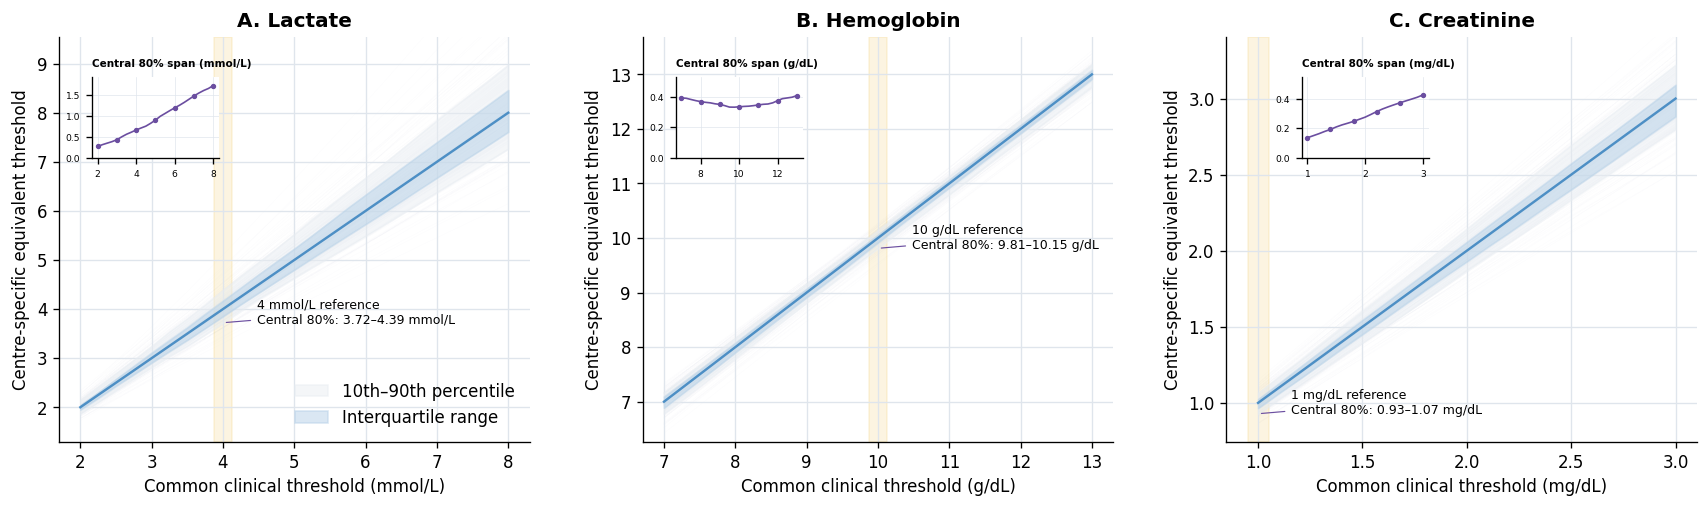

In [15]:
profile_rows = []
profile_center_rows = []
profile_grids = {"Hemoglobin_hour_24": np.arange(7, 13.1, .25),
                 "Lactate_hour_24": np.arange(2, 8.1, .25),
                 "Creatinine_hour_24": np.arange(1, 3.05, .1)}
for variable, grid in profile_grids.items():
    slug = BIOMARKERS[variable]["label"].lower()
    params = pd.read_csv(source_tables / f"{slug}_train70_validate30_rfbbp_threshold_transportability_training_calibration_parameters.csv")
    for reference_value in grid:
        reference_analysis = np.log(reference_value) if BIOMARKERS[variable]["scale"] == "log" else reference_value
        common_state = ((reference_analysis - params.a) / params.b).median()
        equivalent = params.a + params.b * common_state
        if BIOMARKERS[variable]["scale"] == "log":
            equivalent = np.exp(equivalent)
        for center_id, database, value in zip(params.center_id, params.database, equivalent):
            profile_center_rows.append({"variable": variable, "biomarker": BIOMARKERS[variable]["label"],
                                        "center_id": center_id, "database": database,
                                        "reference_value": reference_value, "equivalent_value": value})
        profile_rows.append({"variable": variable, "biomarker": BIOMARKERS[variable]["label"],
                             "reference_value": reference_value, "equivalent_p10": equivalent.quantile(.10),
                             "equivalent_p25": equivalent.quantile(.25), "equivalent_median": equivalent.median(),
                             "equivalent_p75": equivalent.quantile(.75), "equivalent_p90": equivalent.quantile(.90)})
threshold_profiles = pd.DataFrame(profile_rows)
threshold_profile_centres = pd.DataFrame(profile_center_rows)
threshold_profiles.to_csv(TABLES / "three_biomarker_threshold_profiles.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
highlight_values = {"Lactate": 4.0, "Hemoglobin": 10.0, "Creatinine": 1.0}
for panel, (ax, label) in enumerate(zip(axes, ["Lactate", "Hemoglobin", "Creatinine"]), start=1):
    p = threshold_profiles.loc[threshold_profiles.biomarker.eq(label)].sort_values("reference_value")
    centre_profiles = threshold_profile_centres.loc[(threshold_profile_centres.biomarker.eq(label)) & threshold_profile_centres.database.eq("eicu")]
    unit = BIOMARKERS[[k for k,v in BIOMARKERS.items() if v['label']==label][0]]["unit"]
    for _, centre in centre_profiles.groupby("center_id", sort=False):
        ax.plot(centre.reference_value, centre.equivalent_value, color="#9AA3AD", lw=.25, alpha=.028, zorder=1)
    ax.plot(p.reference_value, p.reference_value, color="#555555", lw=.85, ls=(0, (4, 4)), alpha=.42,
            label="_nolegend_", zorder=2)
    ax.fill_between(p.reference_value, p.equivalent_p10, p.equivalent_p90, color="#E8EDF2", alpha=.48,
                    label="10th–90th percentile", zorder=2)
    ax.fill_between(p.reference_value, p.equivalent_p25, p.equivalent_p75, color="#B8D2E8", alpha=.52,
                    label="Interquartile range", zorder=3)
    ax.plot(p.reference_value, p.equivalent_median, color="#4D8FC5", lw=1.45, zorder=4)
    highlight = highlight_values[label]
    nearest = p.iloc[(p.reference_value-highlight).abs().argmin()]
    ax.axvspan(highlight-(p.reference_value.diff().median()/2), highlight+(p.reference_value.diff().median()/2), color="#f1c75b", alpha=.18)
    ax.annotate(f"{highlight:g} {unit} reference\nCentral 80%: {nearest.equivalent_p10:.2f}–{nearest.equivalent_p90:.2f} {unit}",
                xy=(highlight, nearest.equivalent_p10), xytext=(highlight + .08*(p.reference_value.max()-p.reference_value.min()), nearest.equivalent_p10),
                fontsize=7.5, arrowprops={"arrowstyle":"-", "color":"#6b4ea0", "lw":.7})
    ax.set(title=f"{chr(64+panel)}. {label}", xlabel=f"Common clinical threshold ({unit})",
           ylabel="Centre-specific equivalent threshold")
    band_low, band_high = p.equivalent_p10.min(), p.equivalent_p90.max()
    band_pad = .08 * (band_high - band_low)
    ax.set_ylim(band_low-band_pad, band_high+band_pad)
    inset_x = .16 if label == "Creatinine" else .07
    inset = ax.inset_axes([inset_x, .70, .27, .20], facecolor="white")
    width = p.equivalent_p90 - p.equivalent_p10
    inset.plot(p.reference_value, width, color="#6b4ea0", marker="o", markevery=4, ms=2.2, lw=1)
    inset.set_title(f"Central 80% span ({unit})", fontsize=6.2, loc="left", fontweight="bold")
    y_pad = {"Lactate": .20, "Creatinine": .12, "Hemoglobin": .12}[label]
    inset.set_ylim(0, width.max()+y_pad)
    inset.tick_params(labelsize=5.5); inset.grid(True, lw=.4)
    inset.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.subplots_adjust(left=.075, right=.985, top=.90, bottom=.15, wspace=.24)
fig.savefig(FIGURES / "three_biomarker_threshold_transportability_profiles.png", bbox_inches="tight"); plt.show()

### five threshold-specific six-panel figures

The complete plotting implementation is contained in the following cell. 
Generated combinations: haemoglobin 8 and 12 g/dL; lactate 4 and 8 mmol/L; creatinine 2 mg/dL.


Examples: lower=eicu_420, higher=eicu_280
                   group     n  changed  percent   ci_low  ci_high
                   Total 10546      488 4.627347 4.242658 5.045078
 Threshold lower\nthan 8  7965      463 5.812932 5.320051 6.348414
Threshold higher\nthan 8  1624       19 1.169951 0.750263 1.820102
 Effectively equal\nto 8   957        6 0.626959 0.287648 1.361058
Saved: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/hemoglobin_reference8_threshold_reclassification_six_panel.png


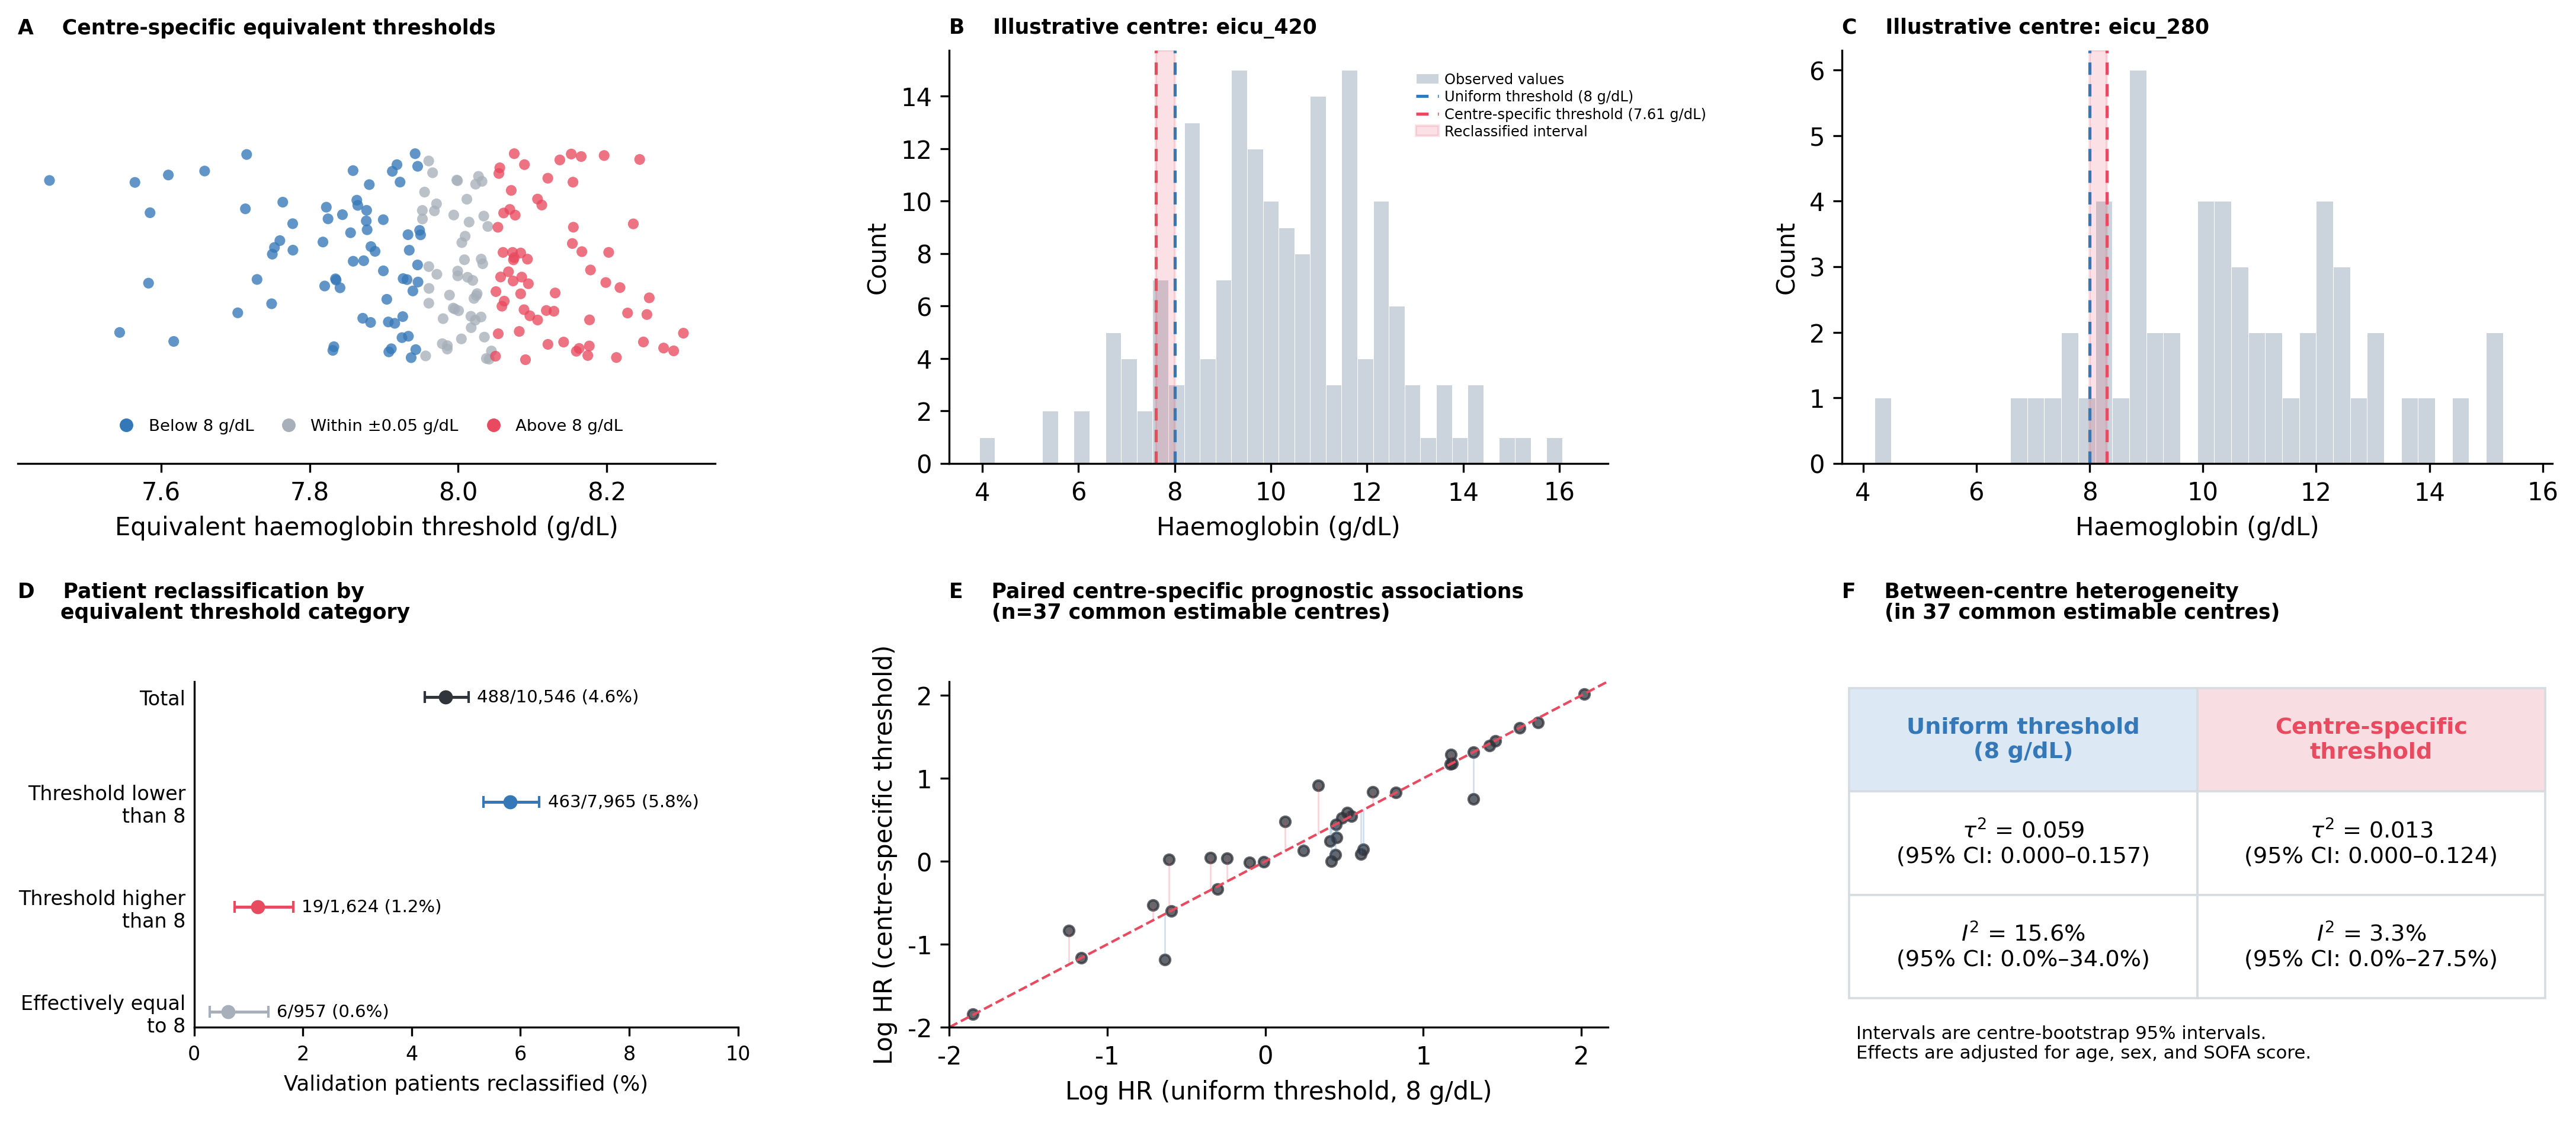

Examples: lower=eicu_148, higher=eicu_144
                    group     n  changed  percent   ci_low  ci_high
                    Total 10546      333 3.157595 2.840532 3.508772
 Threshold lower\nthan 12  7377      299 4.053138 3.626527 4.527577
Threshold higher\nthan 12  1705       25 1.466276 0.995131 2.155627
 Effectively equal\nto 12  1464        9 0.614754 0.323760 1.164239
Saved: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/hemoglobin_reference12_threshold_reclassification_six_panel.png


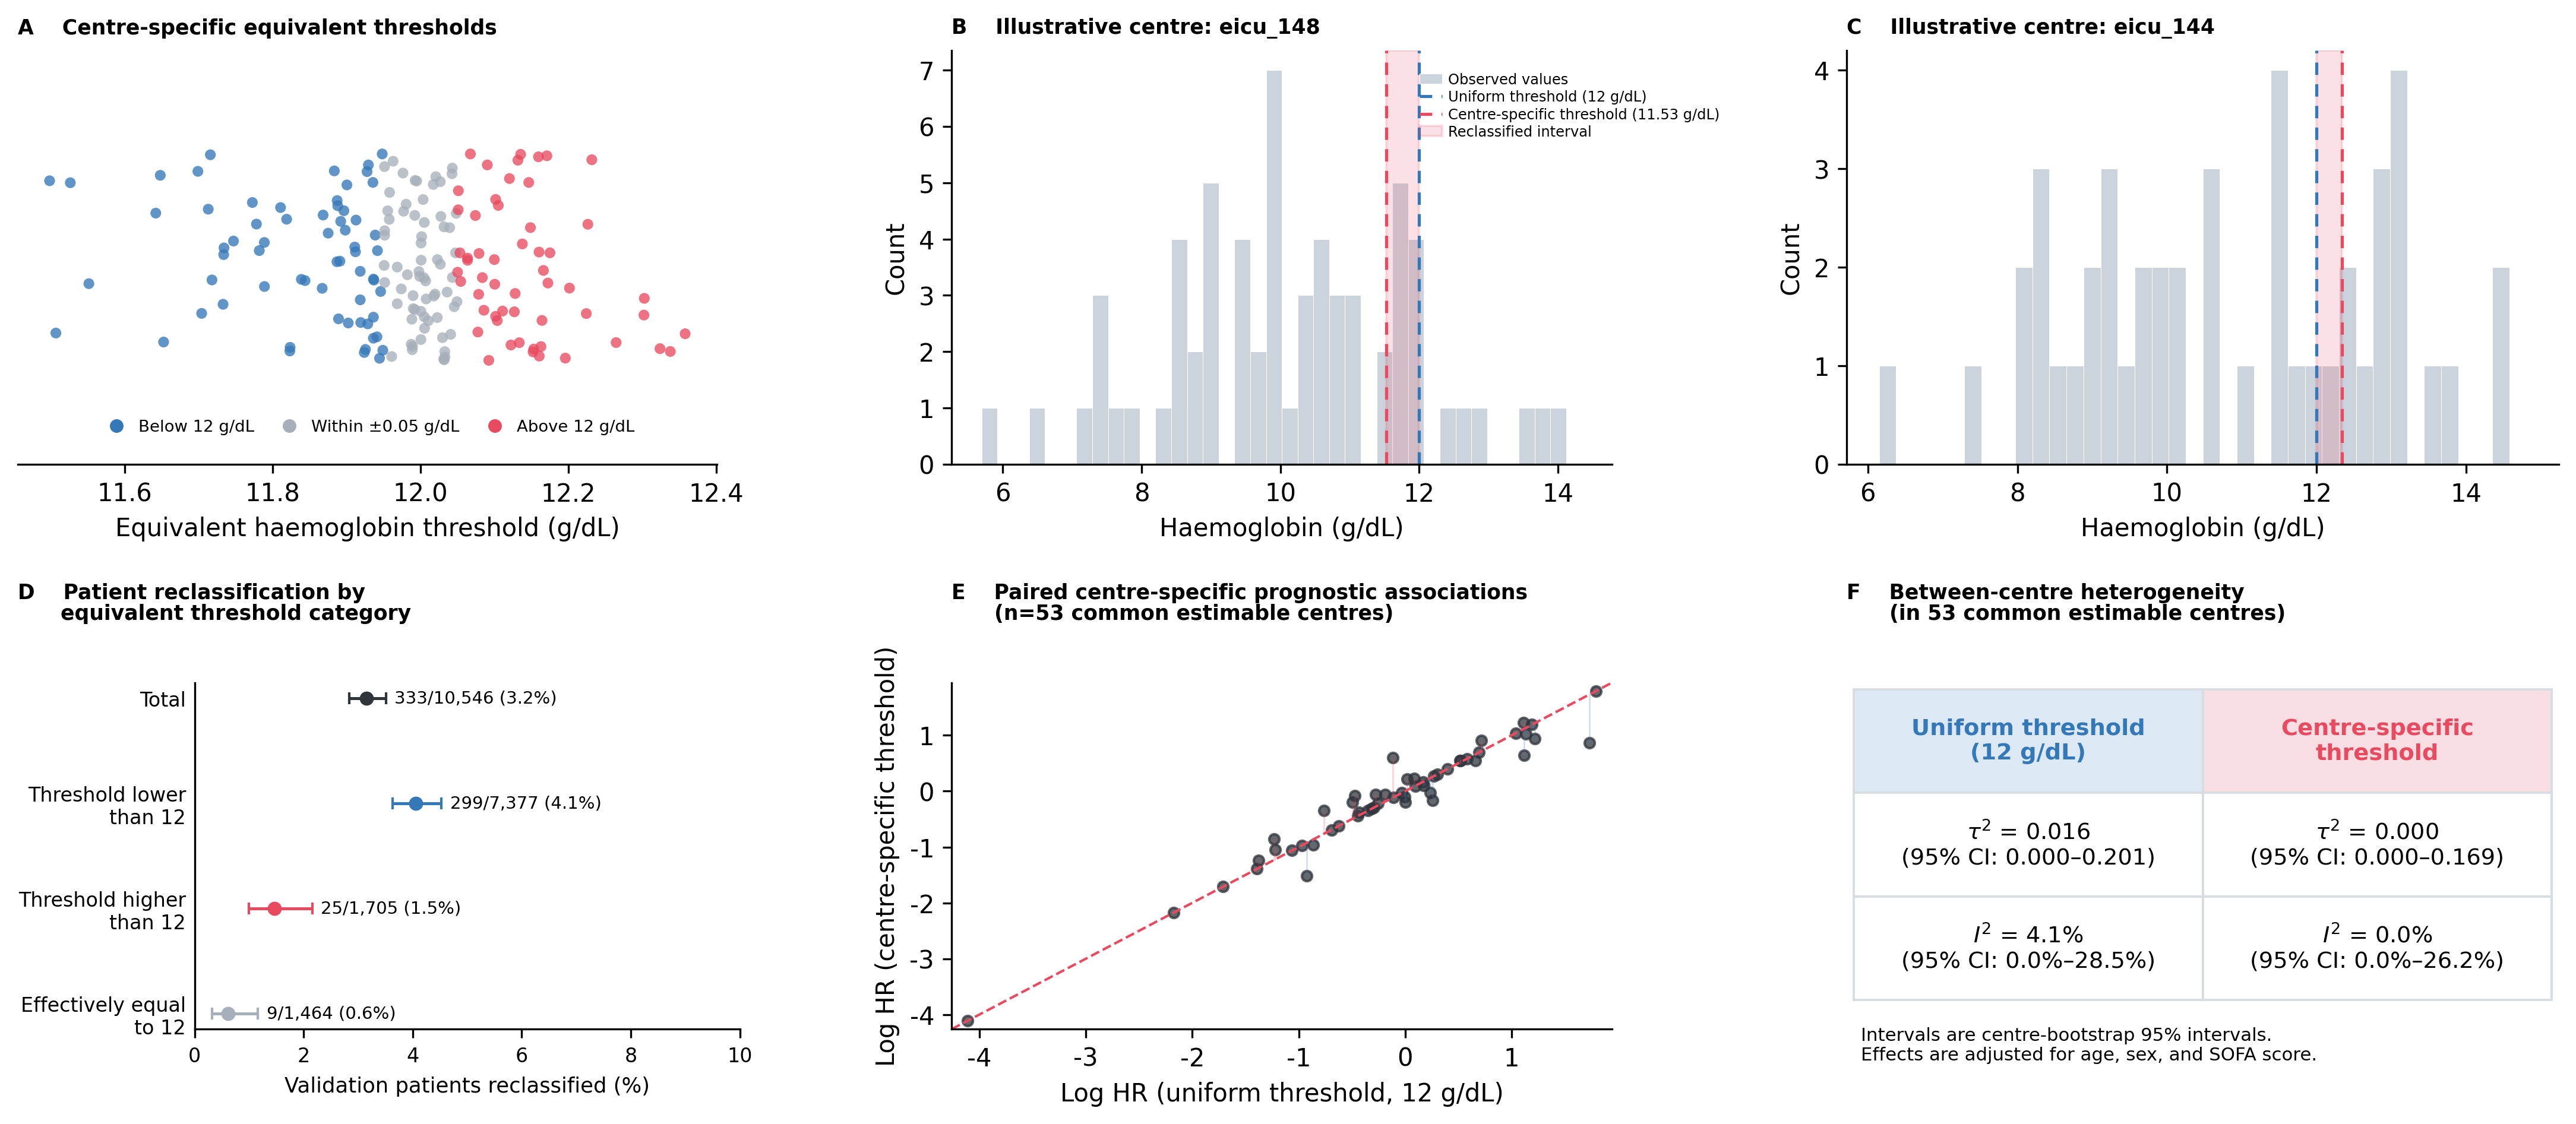

Examples: lower=eicu_416, higher=eicu_199
                   group    n  changed  percent   ci_low  ci_high
                   Total 6893      360 5.222690 4.721962 5.773298
 Threshold lower\nthan 4 5064      323 6.378357 5.737821 7.085024
Threshold higher\nthan 4 1530       37 2.418301 1.759515 3.315420
 Effectively equal\nto 4  299        0 0.000000 0.000000 1.268472
Saved: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/lactate_reference4_threshold_reclassification_six_panel.png


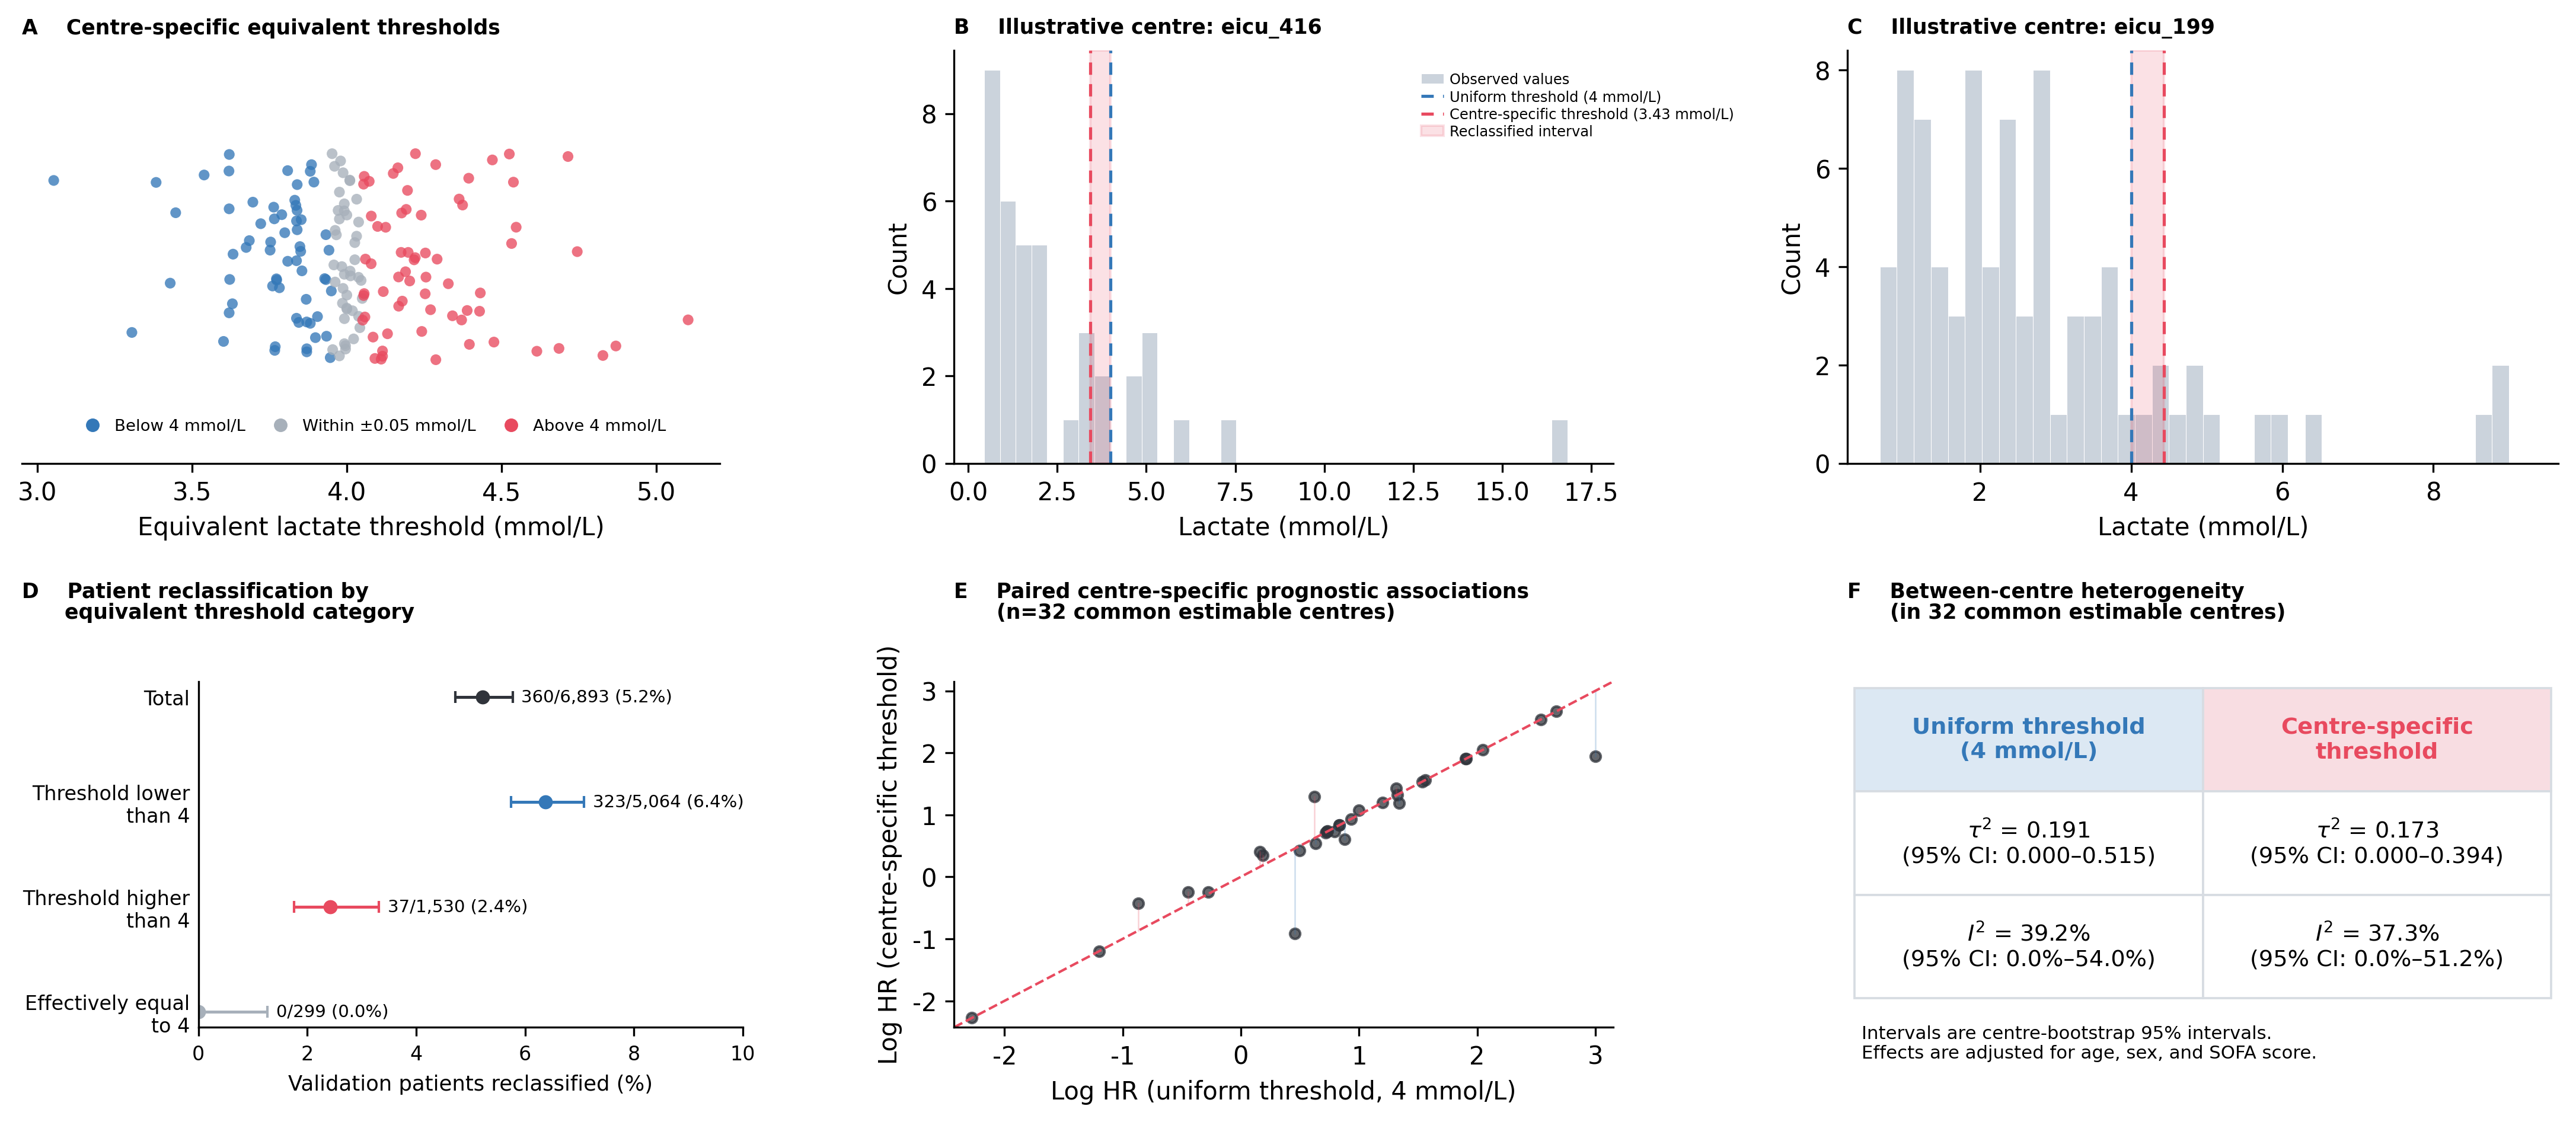

Examples: lower=eicu_275, higher=eicu_167
                   group    n  changed  percent   ci_low  ci_high
                   Total 6893      277 4.018570 3.579971 4.508390
 Threshold lower\nthan 8 5136      247 4.809190 4.257057 5.428873
Threshold higher\nthan 8 1644       30 1.824818 1.281187 2.593060
 Effectively equal\nto 8  113        0 0.000000 0.000000 3.287753
Saved: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/lactate_reference8_threshold_reclassification_six_panel.png


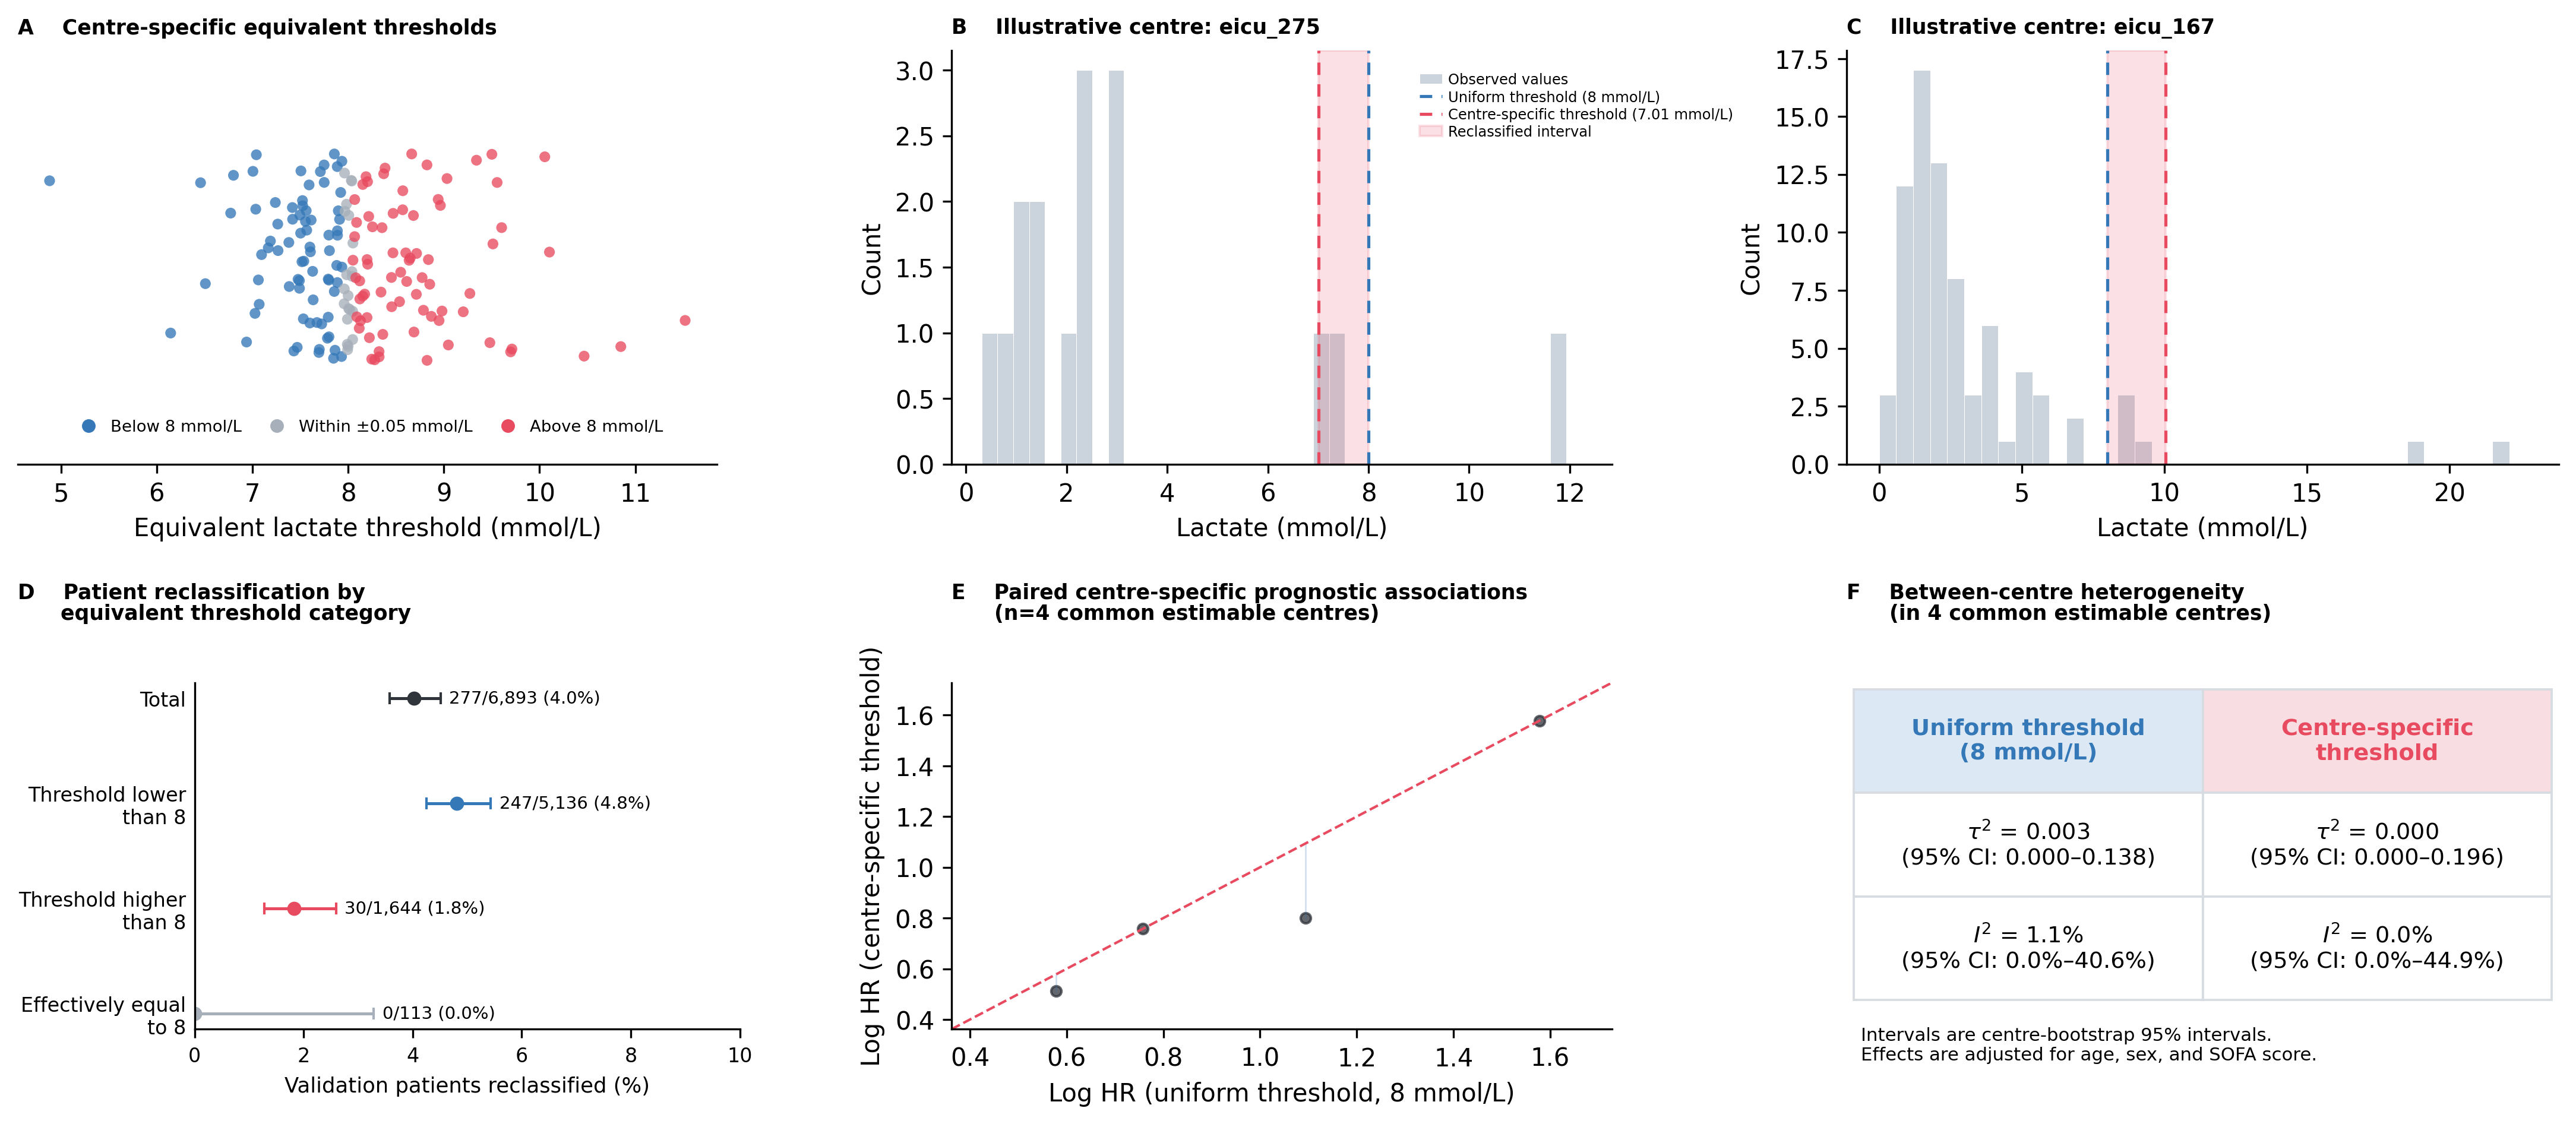

Examples: lower=eicu_244, higher=eicu_208
                   group     n  changed  percent   ci_low  ci_high
                   Total 10729      449 4.184919 3.822127 4.580508
 Threshold lower\nthan 2  6869      382 5.561217 5.043685 6.128426
Threshold higher\nthan 2  1689       58 3.433985 2.665778 4.413530
 Effectively equal\nto 2  2171        9 0.414556 0.218254 0.786025
Saved: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/creatinine_reference2_threshold_reclassification_six_panel.png


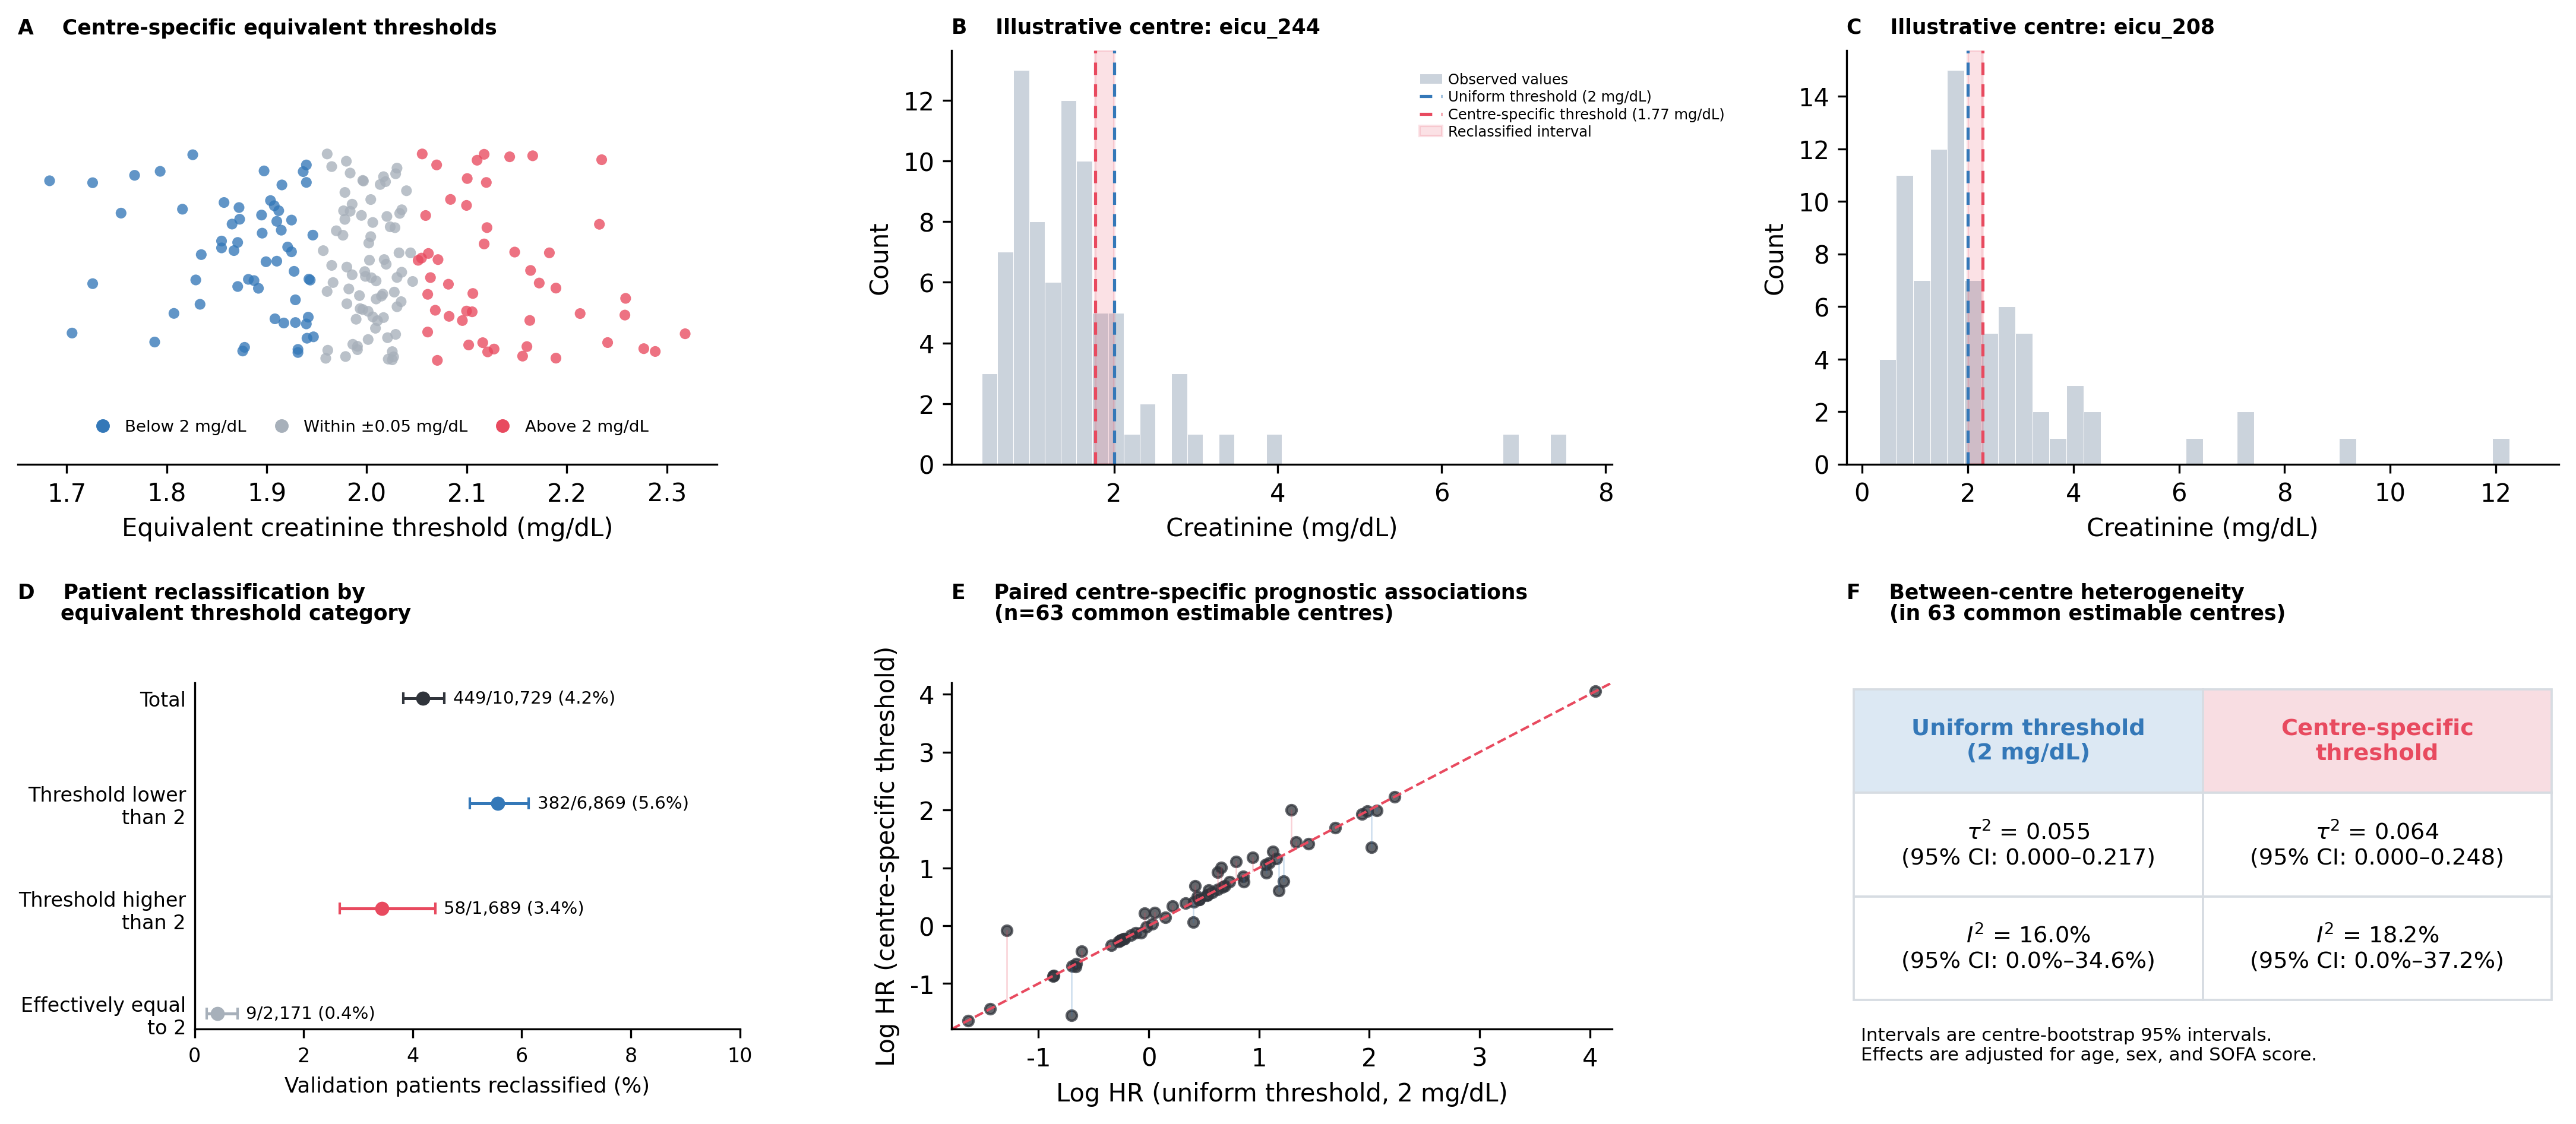

In [20]:
"""Reference-style six-panel threshold figures for the three biomarkers."""

from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.stats import norm
from IPython.display import Image, display


_cwd = Path.cwd().resolve()
if _cwd.name == "analysis_final":
    ROOT = _cwd
elif _cwd.name == "case_multivar":
    ROOT = _cwd / "analysis_final"
elif (_cwd / "case_multivar" / "analysis_final").is_dir():
    ROOT = _cwd / "case_multivar" / "analysis_final"
else:
    raise FileNotFoundError("Could not locate case_multivar/analysis_final.")
RESULTS, TABLES, FIGURES = ROOT / "RFBBP_result", ROOT / "tables", ROOT / "figures"
EQUAL_TOL, SEED = 0.05, 20261020
BLUE, RED, GREY, DARK = "#3478B8", "#E84A5F", "#A7B0BA", "#30343B"
SUMMARY_COLORS = ["#30343B", BLUE, RED, GREY]

# Requested figures. ``low`` records which side of the threshold defines the
# prognostic exposure, matching the analysis that produced the effect tables.
THRESHOLDS = {
    "Hemoglobin_hour_24": [8.0, 12.0],
    "Lactate_hour_24": [4.0, 8.0],
    "Creatinine_hour_24": [2.0],
}
CONFIG = {
    "Hemoglobin_hour_24": {"label": "Hemoglobin", "display": "Haemoglobin", "unit": "g/dL", "low": True},
    "Lactate_hour_24": {"label": "Lactate", "display": "Lactate", "unit": "mmol/L", "low": False},
    "Creatinine_hour_24": {"label": "Creatinine", "display": "Creatinine", "unit": "mg/dL", "low": False},
}


def wilson(k: int, n: int) -> tuple[float, float]:
    if n == 0:
        return np.nan, np.nan
    z, p = norm.ppf(.975), k / n
    denominator = 1 + z*z/n
    centre = (p + z*z/(2*n)) / denominator
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    return 100*(centre-half), 100*(centre+half)


def tau2_dl(log_hr: np.ndarray, se: np.ndarray) -> float:
    variance = se**2
    weights = 1 / variance
    fixed = np.sum(weights*log_hr) / np.sum(weights)
    q = np.sum(weights*(log_hr-fixed)**2)
    c = np.sum(weights) - np.sum(weights**2)/np.sum(weights)
    return max(0.0, (q-(len(log_hr)-1))/c) if c > 0 and len(log_hr) > 1 else 0.0


def tau2_bootstrap_ci(data: pd.DataFrame, seed: int, draws: int = 5000) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    values = np.empty(draws)
    for index in range(draws):
        sampled = data.iloc[rng.integers(0, len(data), len(data))]
        values[index] = tau2_dl(sampled.log_hr.to_numpy(float), sampled.se.to_numpy(float))
    return tuple(np.quantile(values, [.025, .975]))


def heterogeneity_stats(log_hr: np.ndarray, se: np.ndarray) -> tuple[float, float]:
    """DerSimonian-Laird tau-squared and the corresponding I-squared (%)."""
    variance = se**2
    weights = 1 / variance
    fixed = np.sum(weights * log_hr) / np.sum(weights)
    q = np.sum(weights * (log_hr - fixed)**2)
    degrees = len(log_hr) - 1
    c = np.sum(weights) - np.sum(weights**2) / np.sum(weights)
    tau2 = max(0.0, (q - degrees) / c) if c > 0 and degrees > 0 else 0.0
    i2 = max(0.0, 100 * (q - degrees) / q) if q > 0 and degrees > 0 else 0.0
    return tau2, i2


def paired_heterogeneity_bootstrap(effects: pd.DataFrame, seed: int, draws: int = 5000) -> dict[str, tuple[float, float]]:
    """Centre bootstrap retaining the paired estimates from both strategies."""
    wide = effects.pivot(index="center_id", columns="method", values=["log_hr", "se"]).dropna()
    rng = np.random.default_rng(seed)
    sampled_stats = np.empty((draws, 6))
    for draw in range(draws):
        indices = rng.integers(0, len(wide), len(wide))
        u_tau, u_i2 = heterogeneity_stats(
            wide["log_hr", "Uniform"].to_numpy()[indices],
            wide["se", "Uniform"].to_numpy()[indices],
        )
        c_tau, c_i2 = heterogeneity_stats(
            wide["log_hr", "RFBBP-equivalent"].to_numpy()[indices],
            wide["se", "RFBBP-equivalent"].to_numpy()[indices],
        )
        sampled_stats[draw] = u_tau, c_tau, c_tau-u_tau, u_i2, c_i2, c_i2-u_i2
    names = ["u_tau", "c_tau", "d_tau", "u_i2", "c_i2", "d_i2"]
    return {name: tuple(np.quantile(sampled_stats[:, index], [.025, .975]))
            for index, name in enumerate(names)}


def load_validation(variable: str) -> pd.DataFrame:
    data = pd.read_csv(RESULTS / f"{variable}_sofa_adjusted.csv")
    data = pd.concat([group for _, group in data.groupby("center_id", sort=False)], ignore_index=True)
    data["center_id"] = data.center_id.astype(str)
    split = pd.read_csv(
        RESULTS / "three_biomarkers_train70_validate30_rfbbp_threshold_transportability_split_assignment.csv",
        dtype={"center_id": str},
    )
    split = split.loc[split.biomarker.eq(CONFIG[variable]["label"])].reset_index(drop=True)
    if len(data) != len(split) or not data.center_id.equals(split.center_id):
        raise ValueError(f"Saved validation split is not aligned with the {variable} dataset.")
    for column in ["time", "event", "exposure_analysis"]:
        if not np.allclose(data[column], split[column]):
            raise ValueError(f"Saved validation split mismatch: {column}")
    data["split"] = split.split.to_numpy()
    return data.loc[data.split.eq("validation")].copy()


def reclassification_summary(validation: pd.DataFrame, thresholds: pd.DataFrame,
                             reference: float, low_is_abnormal: bool) -> pd.DataFrame:
    data = validation.merge(thresholds[["center_id", "equivalent_threshold"]], on="center_id", validate="many_to_one")
    if low_is_abnormal:
        data["uniform_flag"] = data.exposure_raw.le(reference)
        data["rfbbp_flag"] = data.exposure_raw.le(data.equivalent_threshold)
    else:
        data["uniform_flag"] = data.exposure_raw.ge(reference)
        data["rfbbp_flag"] = data.exposure_raw.ge(data.equivalent_threshold)
    data["changed"] = data.uniform_flag.ne(data.rfbbp_flag)
    delta = data.equivalent_threshold - reference
    ref = f"{reference:g}"
    data["threshold_group"] = np.where(delta < -EQUAL_TOL, f"Threshold lower\nthan {ref}",
                                np.where(delta > EQUAL_TOL, f"Threshold higher\nthan {ref}",
                                         f"Effectively equal\nto {ref}"))
    rows = []
    for label, group in [("Total", data), *data.groupby("threshold_group", sort=False)]:
        n, changed = len(group), int(group.changed.sum())
        low, high = wilson(changed, n)
        rows.append({"group": label, "n": n, "changed": changed, "percent": 100*changed/n,
                     "ci_low": low, "ci_high": high})
    order = ["Total", f"Threshold lower\nthan {ref}", f"Threshold higher\nthan {ref}",
             f"Effectively equal\nto {ref}"]
    return pd.DataFrame(rows).set_index("group").reindex(order).dropna(how="all").reset_index(), data


def draw_example(ax, data: pd.DataFrame, centre: str, threshold: float, title: str,
                 reference: float, display: str, unit: str) -> None:
    values = data.loc[data.center_id.eq(centre), "exposure_raw"]
    value_range = max(values.max() - values.min(), np.finfo(float).eps)
    bin_width = value_range / 36
    lower_edge = np.floor(values.min()/bin_width)*bin_width
    upper_edge = np.ceil(values.max()/bin_width)*bin_width
    bins = np.arange(lower_edge, upper_edge + 1.01*bin_width, bin_width)
    ax.hist(values, bins=bins, color="#CBD3DC", edgecolor="white", linewidth=.25,
            label="Observed values")
    ax.axvline(reference, color=BLUE, ls=(0, (4, 3)), lw=1.25,
               label=f"Uniform threshold ({reference:g} {unit})")
    ax.axvline(threshold, color=RED, ls=(0, (4, 3)), lw=1.25,
               label=f"Centre-specific threshold ({threshold:.2f} {unit})")
    ax.axvspan(min(reference, threshold), max(reference, threshold), color=RED, alpha=.16,
               label="Reclassified interval")
    ax.set_title(title, loc="left", fontsize=10, weight="bold", fontfamily="DejaVu Sans")
    ax.set_xlabel(f"{display} ({unit})"); ax.set_ylabel("Count")
    ax.grid(False); ax.spines[["top", "right"]].set_visible(False)


def build_one(variable: str, reference: float) -> None:
    cfg = CONFIG[variable]
    thresholds = pd.read_csv(TABLES / "requested_centre_equivalent_thresholds.csv", dtype={"center_id": str})
    thresholds = thresholds.loc[
        thresholds.variable.eq(variable) & thresholds.reference_value.eq(reference)
    ].sort_values("equivalent_threshold").reset_index(drop=True)
    validation = load_validation(variable)
    summary, classified = reclassification_summary(validation, thresholds, reference, cfg["low"])
    stem = f"{cfg['label'].lower()}_reference{reference:g}".replace(".", "p")
    summary.to_csv(TABLES / f"{stem}_reclassification_summary.csv", index=False)

    effects = pd.read_csv(TABLES / "heldout_main_threshold_centre_effects.csv", dtype={"center_id": str})
    effects = effects.loc[
        effects.variable.eq(variable) & effects.reference_value.eq(reference)
        & effects.common_center.eq(True)
    ].copy()
    meta = pd.read_csv(TABLES / "heldout_threshold_meta_heterogeneity.csv")
    meta = meta.loc[meta.variable.eq(variable) & meta.reference_value.eq(reference)]
    hr = effects.pivot(index="center_id", columns="method", values=["log_hr", "se", "hr"])
    common = hr.index

    # Representative centres: largest number reclassified in each direction,
    # excluding the much larger MIMIC-IV centre so both histograms remain legible.
    by_centre = classified.groupby("center_id").agg(
        n=("event", "size"), changed=("changed", "sum"), threshold=("equivalent_threshold", "first")
    )
    lower = by_centre.loc[(by_centre.threshold < reference-EQUAL_TOL) & by_centre.index.str.startswith("eicu_")]
    higher = by_centre.loc[(by_centre.threshold > reference+EQUAL_TOL) & by_centre.index.str.startswith("eicu_")]
    ranked = by_centre.loc[by_centre.index.str.startswith("eicu_")].sort_values(["changed", "n"], ascending=False)
    lower_id = lower.sort_values(["changed", "n"], ascending=False).index[0] if len(lower) else ranked.index[0]
    higher_id = higher.sort_values(["changed", "n"], ascending=False).index[0] if len(higher) else ranked.index[1]

    fig = plt.figure(figsize=(15.5, 6.8), dpi=300, facecolor="white")
    grid = fig.add_gridspec(2, 3, height_ratios=[.82, .88], width_ratios=[1.08, 1.02, 1.10],
                            hspace=.40, wspace=.34)
    ax_a, ax_b, ax_c = (fig.add_subplot(grid[0, index]) for index in range(3))
    ax_d, ax_e, ax_f = (fig.add_subplot(grid[1, index]) for index in range(3))

    rng = np.random.default_rng(SEED)
    jitter = rng.uniform(-.065, .065, len(thresholds))
    threshold_delta = thresholds.equivalent_threshold - reference
    threshold_colours = np.where(
        threshold_delta < -EQUAL_TOL, BLUE,
        np.where(threshold_delta > EQUAL_TOL, RED, GREY),
    )
    ax_a.scatter(thresholds.equivalent_threshold, jitter, s=19, c=threshold_colours,
                 alpha=.78, linewidth=0)
    ax_a.set(xlabel=f"Equivalent {cfg['display'].lower()} threshold ({cfg['unit']})", yticks=[], ylim=(-.13, .13))
    ax_a.set_title("A    Centre-specific equivalent thresholds",
                   fontsize=8.5, weight="bold", fontfamily="DejaVu Sans", loc="left", pad=6)
    category_handles = [
        Line2D([], [], marker="o", linestyle="none", color=BLUE, markersize=4.5, label=f"Below {reference:g} {cfg['unit']}"),
        Line2D([], [], marker="o", linestyle="none", color=GREY, markersize=4.5,
               label=f"Within ±{EQUAL_TOL:g} {cfg['unit']}"),
        Line2D([], [], marker="o", linestyle="none", color=RED, markersize=4.5, label=f"Above {reference:g} {cfg['unit']}"),
    ]
    ax_a.legend(handles=category_handles, ncol=3, loc="lower center", bbox_to_anchor=(.5, .055),
                frameon=False, fontsize=6.6, handletextpad=.35, columnspacing=1.15, borderaxespad=0)
    ax_a.grid(False); ax_a.spines[["top", "right", "left"]].set_visible(False)

    lower_n = int(by_centre.loc[lower_id, "n"]); lower_changed = int(by_centre.loc[lower_id, "changed"])
    higher_n = int(by_centre.loc[higher_id, "n"]); higher_changed = int(by_centre.loc[higher_id, "changed"])
    draw_example(ax_b, classified, lower_id, by_centre.loc[lower_id, "threshold"],
                 f"B    Illustrative centre: {lower_id}", reference, cfg["display"], cfg["unit"])
    draw_example(ax_c, classified, higher_id, by_centre.loc[higher_id, "threshold"],
                 f"C    Illustrative centre: {higher_id}", reference, cfg["display"], cfg["unit"])
    ax_b.title.set_fontsize(8.2); ax_c.title.set_fontsize(8.2)
    # Keep the histogram unobscured: the B plotting area is narrowed below,
    # leaving a dedicated legend strip on its right within the B panel cell.
    legend_options = dict(frameon=False, fontsize=5.8, loc="upper left", bbox_to_anchor=(.70, .96),
                          handlelength=1.55, handletextpad=.42,
                          borderaxespad=0, labelspacing=.22)
    ax_b.legend(**legend_options)
    if ax_c.get_legend() is not None:
        ax_c.get_legend().remove()
    y_summary = np.arange(len(summary))[::-1]
    for colour, y, row in zip(SUMMARY_COLORS, y_summary, summary.itertuples(index=False)):
        ax_d.errorbar(row.percent, y, xerr=[[row.percent-row.ci_low], [row.ci_high-row.percent]],
                       fmt="o", color=colour, ecolor=colour, capsize=2.5, lw=1.2, ms=4.7)
        ax_d.text(row.ci_high+.16, y, f"{row.changed:,}/{row.n:,} ({row.percent:.1f}%)",
                  va="center", fontsize=7.0)
    ax_d.set(yticks=y_summary, yticklabels=summary.group,
             xlabel="Validation patients reclassified (%)")
    ax_d.set_title("D    Patient reclassification by\n      equivalent threshold category", loc="left", fontsize=10.5,
                   weight="bold", fontfamily="DejaVu Sans", pad=7)
    ax_d.title.set_fontsize(8.5)
    ax_d.grid(False); ax_d.spines[["top", "right"]].set_visible(False); ax_d.tick_params(axis="y", length=0, labelsize=8)
    ax_d.tick_params(axis="x", labelsize=8)
    ax_d.xaxis.label.set_size(8.5)
    ax_d.set_xlim(left=0, right=max(10, summary.ci_high.max()+2.5))

    order = hr["log_hr", "Uniform"].sort_values().index
    raw_log = hr["log_hr", "Uniform"].loc[order]; cal_log = hr["log_hr", "RFBBP-equivalent"].loc[order]
    limits = [min(raw_log.min(), cal_log.min())-.15, max(raw_log.max(), cal_log.max())+.15]
    ax_e.scatter(raw_log, cal_log, s=17, color=DARK, alpha=.75)
    for centre in order:
        ax_e.plot([raw_log.loc[centre], raw_log.loc[centre]], [raw_log.loc[centre], cal_log.loc[centre]],
                   color=RED if cal_log.loc[centre] >= raw_log.loc[centre] else BLUE, alpha=.25, lw=.6)
    ax_e.plot(limits, limits, ls="--", color=RED, lw=1)
    ax_e.set(xlim=limits, ylim=limits, xlabel=f"Log HR (uniform threshold, {reference:g} {cfg['unit']})",
             ylabel="Log HR (centre-specific threshold)")
    ax_e.set_title("E    Paired centre-specific prognostic associations\n"
                   f"      (n={len(order)} common estimable centres)", loc="left",
                   fontsize=8.5, weight="bold", fontfamily="DejaVu Sans", pad=6)
    ax_e.grid(False); ax_e.spines[["top", "right"]].set_visible(False)

    ax_f.axis("off")
    ax_f.set_title("F    Between-centre heterogeneity\n"
                   f"      (in {len(order)} common estimable centres)", loc="left", fontsize=9.0,
                   weight="bold", fontfamily="DejaVu Sans", pad=6)
    ax_f.title.set_fontsize(8.5)
    uniform_meta = meta.loc[meta.method.eq("Uniform")].iloc[0]
    calibrated_meta = meta.loc[meta.method.eq("RFBBP-equivalent")].iloc[0]
    intervals = paired_heterogeneity_bootstrap(effects, SEED)
    table_text = [
        [f"Uniform threshold\n({reference:g} {cfg['unit']})", "Centre-specific\nthreshold"],
        [rf"$\tau^2$ = {uniform_meta.tau2:.3f}" + f"\n(95% CI: {intervals['u_tau'][0]:.3f}–{intervals['u_tau'][1]:.3f})",
         rf"$\tau^2$ = {calibrated_meta.tau2:.3f}" + f"\n(95% CI: {intervals['c_tau'][0]:.3f}–{intervals['c_tau'][1]:.3f})"],
        [rf"$I^2$ = {uniform_meta.I2:.1f}%" + f"\n(95% CI: {intervals['u_i2'][0]:.1f}%–{intervals['u_i2'][1]:.1f}%)",
         rf"$I^2$ = {calibrated_meta.I2:.1f}%" + f"\n(95% CI: {intervals['c_i2'][0]:.1f}%–{intervals['c_i2'][1]:.1f}%)"],
    ]
    table = ax_f.table(cellText=table_text, cellLoc="center", loc="center",
                       colWidths=[.5, .5], bbox=[.01, .18, .98, .70])
    table.auto_set_font_size(False); table.set_fontsize(9.2)
    for (row, column), cell in table.get_celld().items():
        cell.set_edgecolor("#D7DCE2"); cell.set_linewidth(.9)
        header_colours = ["#DCE8F3", "#F8DDE2"]
        cell.set_facecolor(header_colours[column] if row == 0 else "white")
        if row == 0:
            cell.get_text().set_weight("bold")
            cell.get_text().set_color(BLUE if column == 0 else RED)
    ax_f.text(.02, .12, "Intervals are centre-bootstrap 95% intervals.\n"
              "Effects are adjusted for age, sex, and SOFA score.",
              transform=ax_f.transAxes, fontsize=7.4, va="top")

    fig.subplots_adjust(left=.065, right=.985, top=.94, bottom=.09)
    # Retain the full B plotting width; place the legend in the inter-panel gutter.
    b_position = ax_b.get_position()
    ax_b.set_position([b_position.x0, b_position.y0, b_position.width, b_position.height])
    # Preserve the regular grid positions for globally aligned panel titles.
    regular_positions = {axis: axis.get_position().frozen() for axis in [ax_a, ax_b, ax_c, ax_d, ax_e, ax_f]}
    # D has long category labels; inset the complete panel so its labels and
    # x-axis title remain within the visual footprint of the lower-left cell.
    d_position = ax_d.get_position()
    ax_d.set_position([
        d_position.x0 + .064,
        d_position.y0 + .042,
        d_position.width * .78,
        d_position.height * .78,
    ])
    # Slightly compress the dense association plot and centre it vertically in
    # the same lower-row band occupied by D and F.
    e_position = ax_e.get_position()
    ax_e.set_position([
        e_position.x0,
        e_position.y0 + .042,
        e_position.width,
        e_position.height * .78,
    ])

    # Axis-attached titles move when panels are inset. Draw all six titles in
    # figure coordinates so font size and first-line baselines are identical.
    for axis in [ax_a, ax_b, ax_c, ax_d, ax_e, ax_f]:
        axis.set_title("", loc="left")
    title_size = 8.3
    top_y = regular_positions[ax_a].y1 + .010
    bottom_y = regular_positions[ax_e].y1 + .010
    panel_titles = [
        (regular_positions[ax_a].x0, top_y, "A    Centre-specific equivalent thresholds"),
        (regular_positions[ax_b].x0, top_y, f"B    Illustrative centre: {lower_id}"),
        (regular_positions[ax_c].x0, top_y, f"C    Illustrative centre: {higher_id}"),
        (regular_positions[ax_d].x0, bottom_y,
         "D    Patient reclassification by\n      equivalent threshold category"),
        (regular_positions[ax_e].x0, bottom_y,
         f"E    Paired centre-specific prognostic associations\n      (n={len(order)} common estimable centres)"),
        (regular_positions[ax_f].x0, bottom_y,
         f"F    Between-centre heterogeneity\n      (in {len(order)} common estimable centres)"),
    ]
    for title_x, title_y, title_text in panel_titles:
        fig.text(title_x, title_y, title_text, fontsize=title_size, weight="bold",
                 fontfamily="DejaVu Sans", ha="left", va="bottom", linespacing=1.05)
    out = FIGURES / f"{stem}_threshold_reclassification_six_panel.png"
    fig.savefig(out, bbox_inches="tight")
    if variable == "Hemoglobin_hour_24" and reference == 8.0:
        fig.savefig(FIGURES / "Figure 4.png", bbox_inches="tight")
    plt.close(fig)
    print(f"Examples: lower={lower_id}, higher={higher_id}")
    print(summary.to_string(index=False)); print(f"Saved: {out}")
    display(Image(filename=str(out), width=1100))


def main() -> None:
    for variable, references in THRESHOLDS.items():
        for reference in references:
            build_one(variable, reference)


main()


## 9. Centre heterogeneity before and after latent-scale calibration

The following cell reproduces the three-panel centre-heterogeneity figure for hemoglobin, lactate, and creatinine. Panel A shows the measurement distribution on the scale actually supplied to each RFBBP model (raw $W$ for hemoglobin and $\log(W)$ for lactate and creatinine); Panel B shows the full posterior distribution of patient-level latent $X$; Panel C compares centre-specific estimates with the overall RFBBP estimate. The same centre colour is retained across all panels.

The complete plotting implementation is contained in the following cell. It can be executed independently of the other notebook cells and does not call an external plotting script. The five previously selected centres and their centre-specific estimates are read from the analysis tables, while the displayed distributions are recalculated directly from the analysis datasets and posterior NetCDF files.

Hemoglobin: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/hemoglobin_centre_heterogeneity_w_x_beta.png


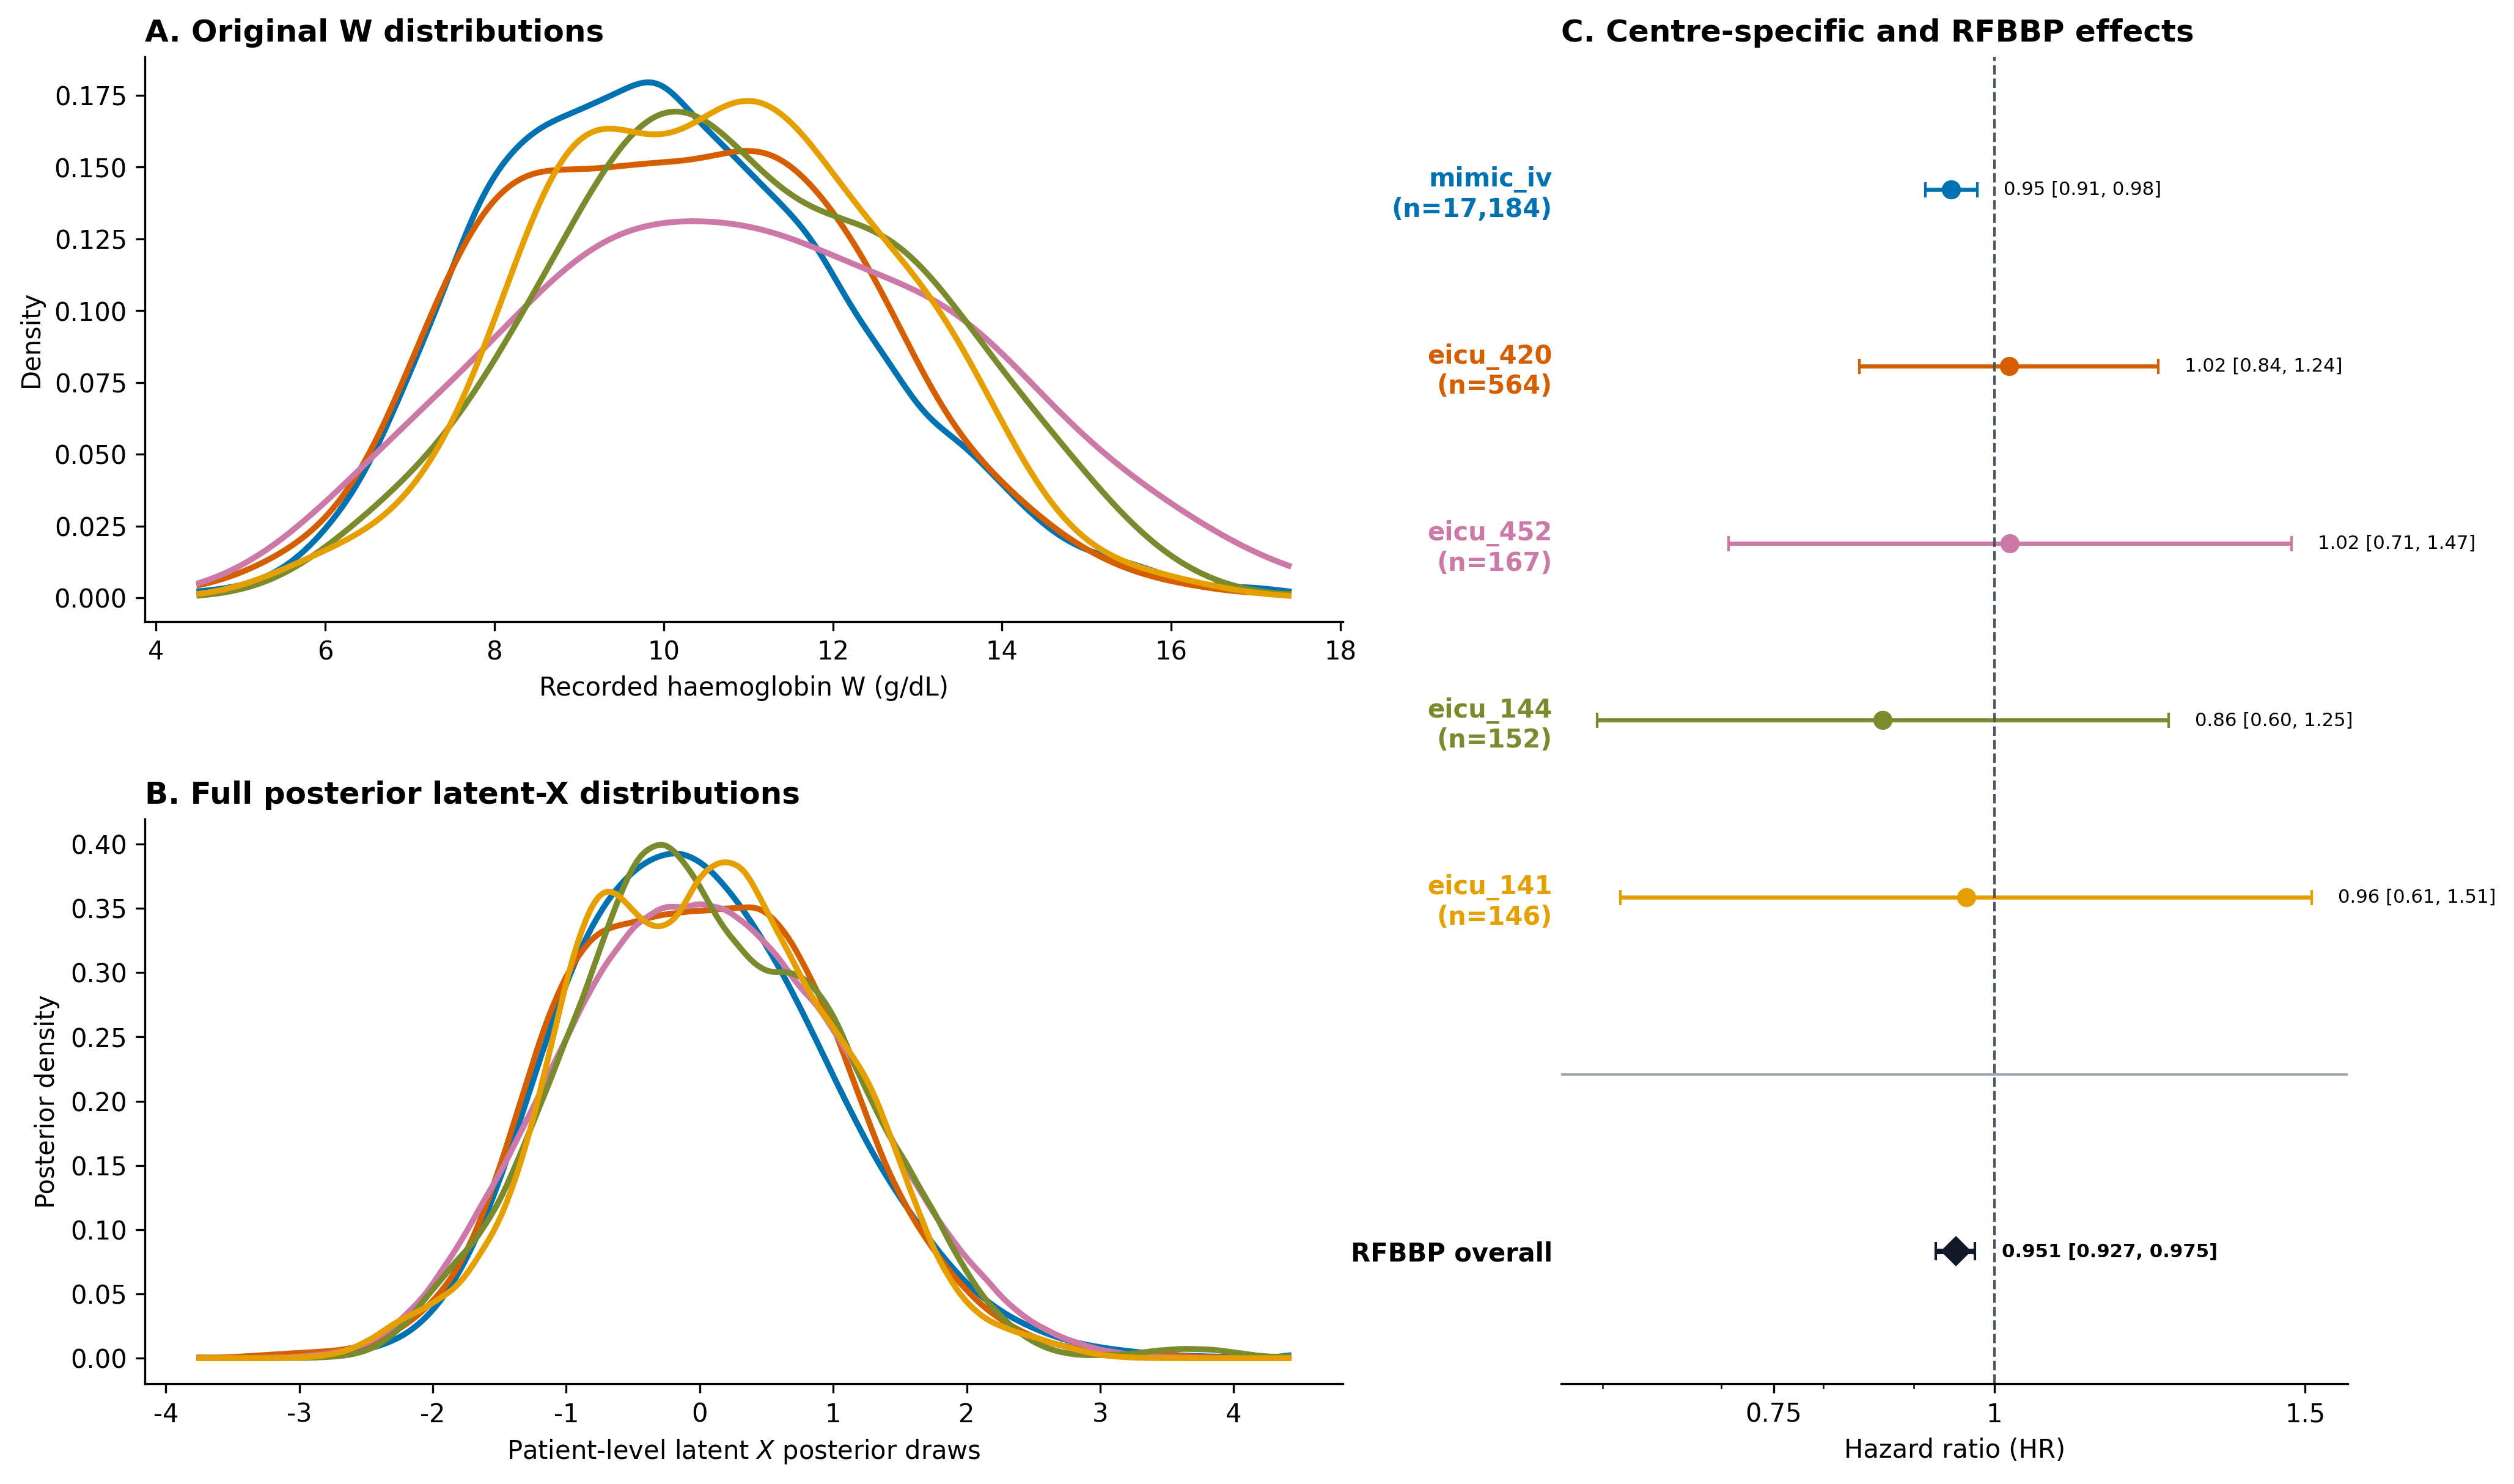

Lactate: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/lactate_centre_heterogeneity_w_x_beta.png


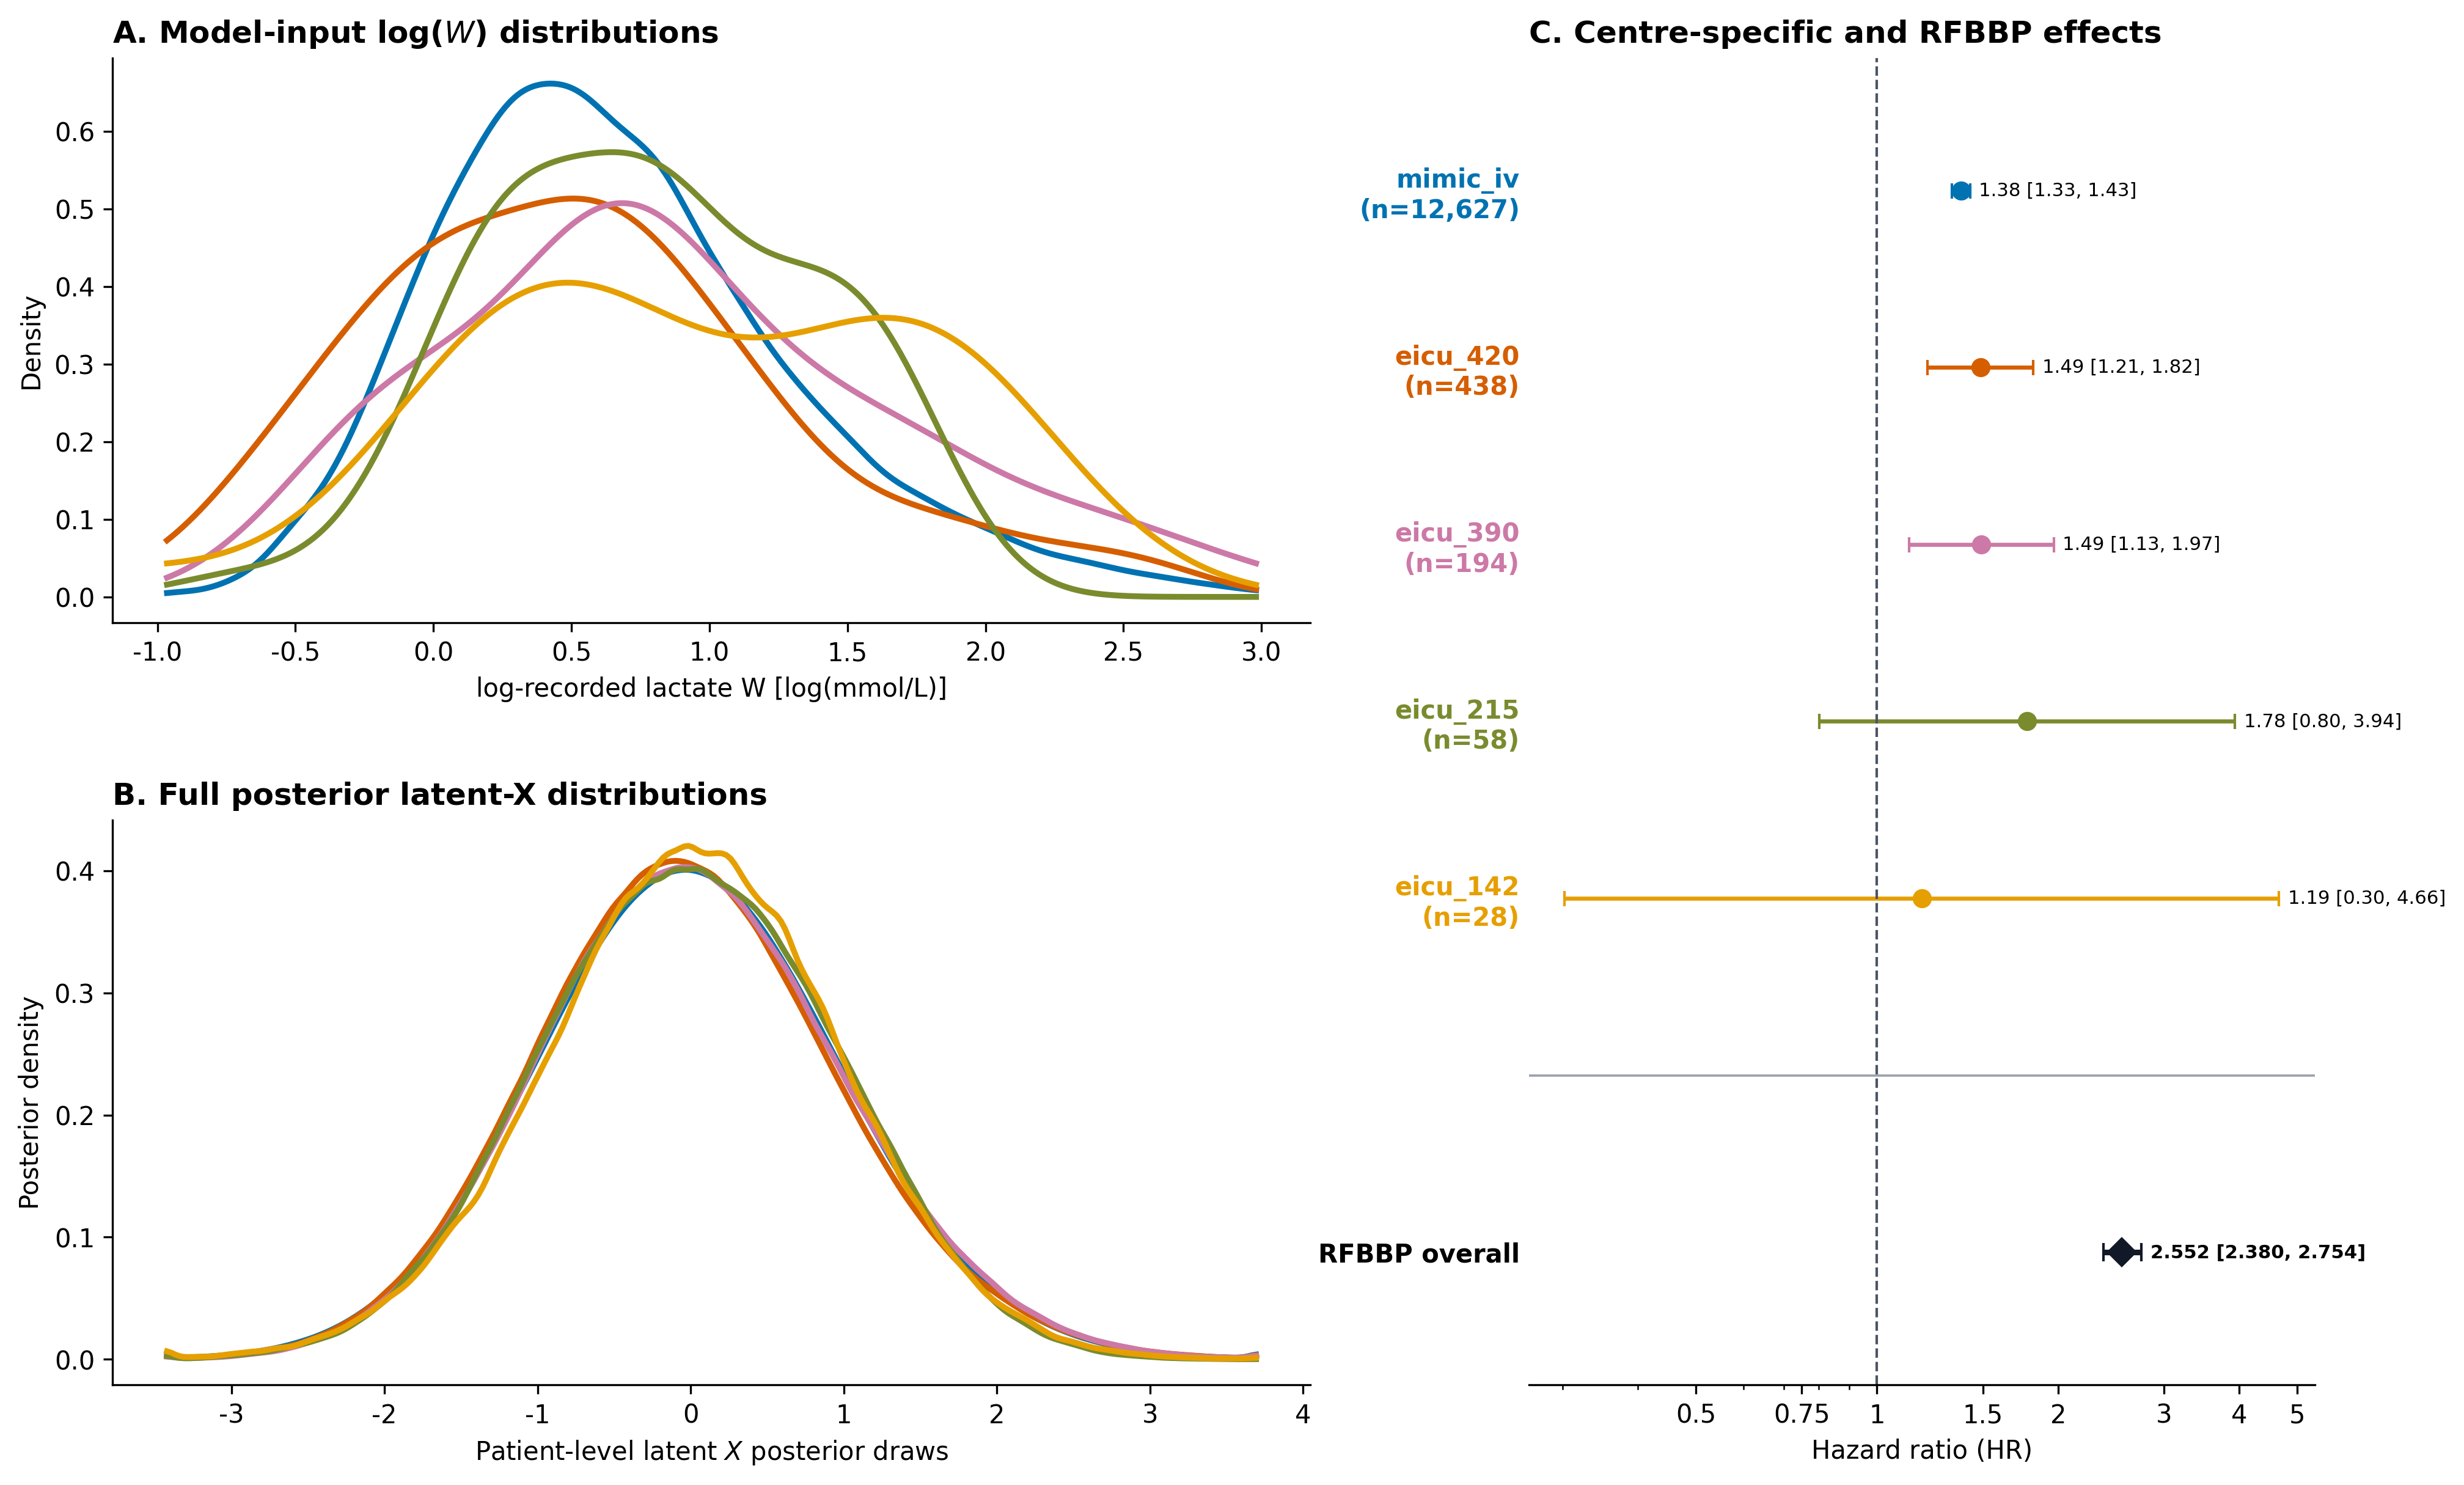

Creatinine: /mnt/e/SongJL/016_research/RFBBP/case_multivar/analysis_final/figures/creatinine_centre_heterogeneity_w_x_beta.png


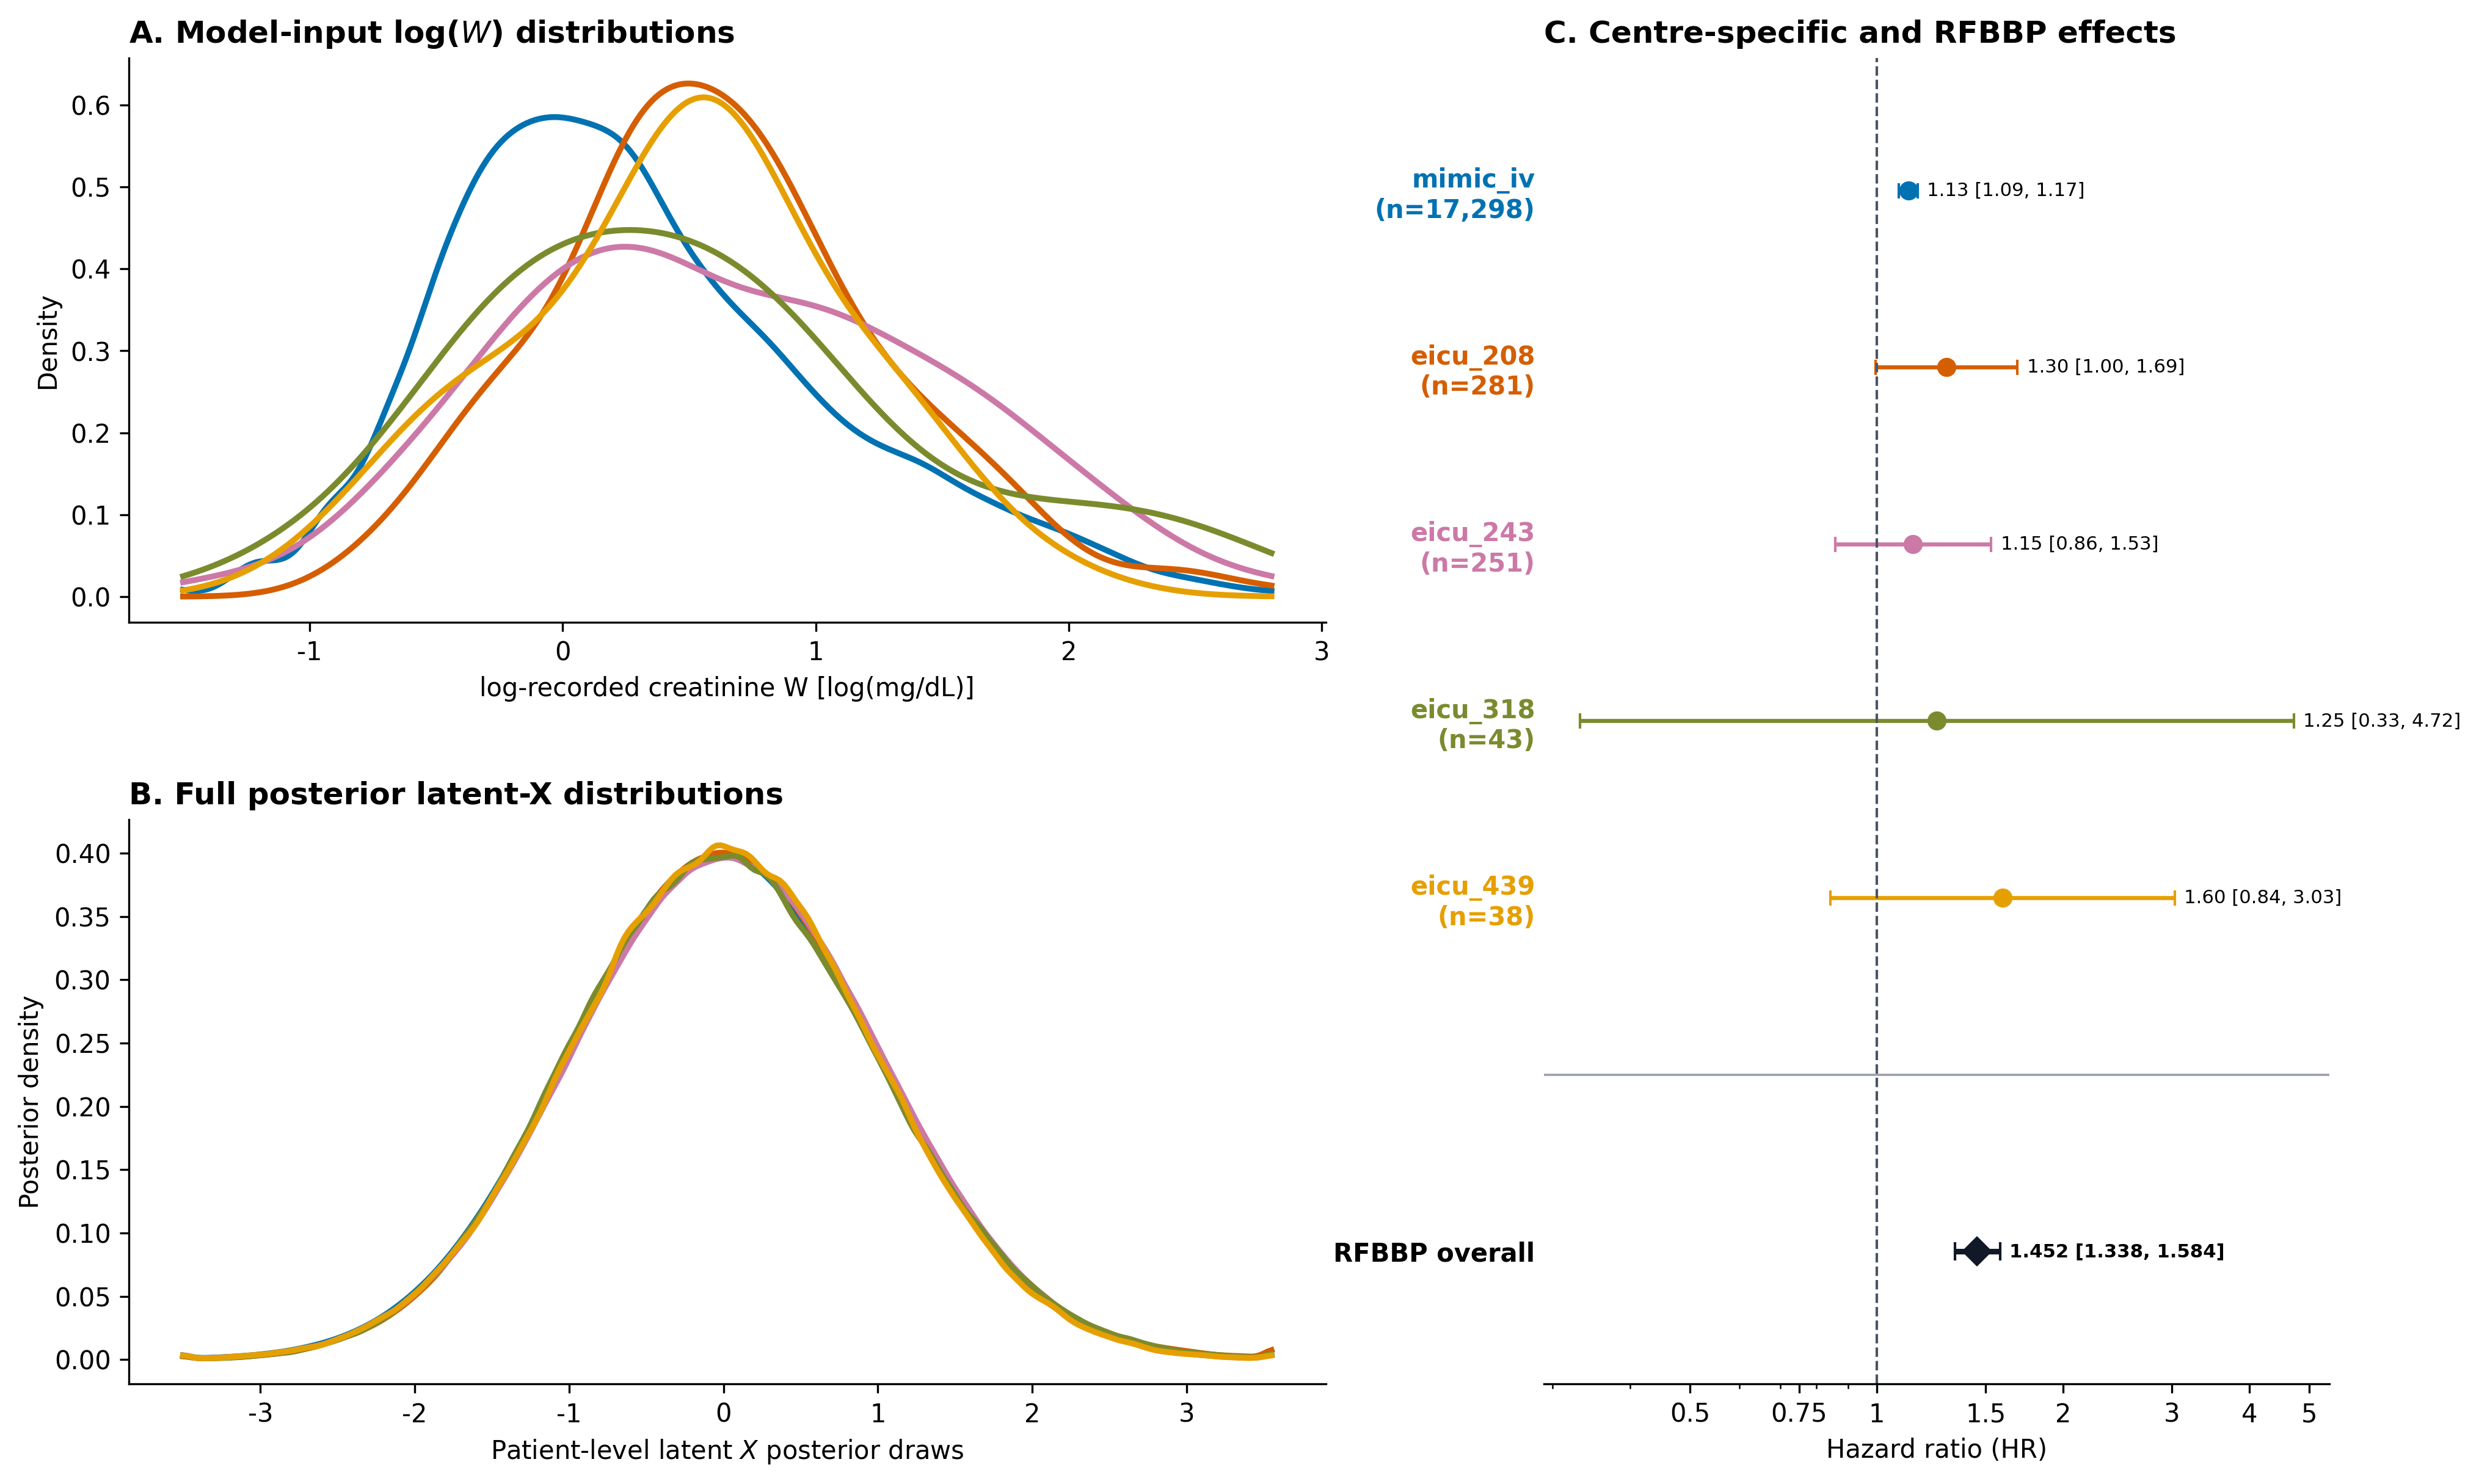

In [18]:
# Standalone centre-heterogeneity figure code: no external .py file is executed.
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Image, display
from scipy.ndimage import gaussian_filter1d
from scipy.stats import gaussian_kde

# Locate analysis_final regardless of whether the notebook is launched from
# the repository root, case_multivar, or analysis_final itself.
_cwd = Path.cwd().resolve()
if _cwd.name == "analysis_final":
    HET_ROOT = _cwd
elif _cwd.name == "case_multivar":
    HET_ROOT = _cwd / "analysis_final"
elif (_cwd / "case_multivar" / "analysis_final").is_dir():
    HET_ROOT = _cwd / "case_multivar" / "analysis_final"
else:
    raise FileNotFoundError("Could not locate case_multivar/analysis_final.")

HET_DATA = HET_ROOT / "analysis_datasets"
HET_TABLES = HET_ROOT / "tables"
HET_FIGURES = HET_ROOT / "figures"
HET_MODELS = HET_ROOT.parent / "analysis_simple" / "output" / "direct_rfbbp_hierarchical_all_metrics_w_raw"
HET_RESULTS = HET_ROOT / "RFBBP_result"
HET_FIGURES.mkdir(parents=True, exist_ok=True)

HET_COLORS = ["#0072B2", "#D55E00", "#CC79A7", "#7A8B2E", "#E69F00"]
HET_N_BINS = 260
HET_DRAW_CHUNK = 100
HET_CONFIGS = [
    {
        "key": "hemoglobin", "variable": "Hemoglobin_hour_24",
        "label": "Hemoglobin", "display_label": "haemoglobin", "unit": "g/dL", "figure_alias": "Figure 3.png",
        "log_w": False,
        "model": "Hemoglobin_hour_24_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_clean_no_comorbidity_linear_mimic_eicu_all_hb_lactate.nc",
        "summary": "Hemoglobin_hour_24_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_no_center_filter_mimic_eicu_summary.csv",
    },
    {
        "key": "lactate", "variable": "Lactate_hour_24",
        "label": "Lactate", "display_label": "lactate", "unit": "mmol/L", "figure_alias": "Figure 3-2.png",
        "log_w": True,
        "model": "Lactate_hour_24_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_clean_no_comorbidity_linear_mimic_eicu_all_hb_lactate.nc",
        "summary": "Lactate_hour_24_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_no_center_filter_mimic_eicu_summary.csv",
    },
    {
        "key": "creatinine", "variable": "Creatinine_hour_24",
        "label": "Creatinine", "display_label": "creatinine", "unit": "mg/dL", "figure_alias": "Figure 3-1.png",
        "log_w": True,
        "model": "Creatinine_hour_24_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_clean_no_comorbidity_linear_mimic_eicu_all_creatinine_ta098.nc",
        "summary": "Creatinine_hour_24_sofa_adjusted_mimic_iv_eicu_w_raw_rfbbp_hierarchical_5interval_no_center_filter_mimic_eicu_summary.csv",
    },
]

def _heterogeneity_load(config):
    data = pd.read_csv(
        HET_DATA / f"{config['variable']}_sofa_adjusted.csv",
        usecols=["database", "center_id", "exposure_raw"],
    ).dropna().reset_index(drop=True)
    data["center_id"] = data["center_id"].astype(str)
    model_path = HET_MODELS / config["model"]
    observed = xr.open_dataset(model_path, group="observed_data")["W_obs"].values
    expected = np.log(data.exposure_raw.to_numpy(float)) if config["log_w"] else data.exposure_raw.to_numpy(float)
    if len(observed) != len(data) or not np.allclose(observed, expected):
        raise ValueError(f"Model-row/scale audit failed for {config['label']}.")
    posterior_x = xr.open_dataset(model_path, group="posterior")["x"]
    selected = pd.read_csv(
        HET_TABLES / f"{config['key']}_centers_large_w_difference_small_x_difference.csv",
        dtype={"center_id": str},
    )
    selected = selected.sort_values(["n_patients", "center_id"], ascending=[False, True]).reset_index(drop=True)
    if len(selected) != 5 or selected[["beta", "beta_low", "beta_high"]].isna().any().any():
        raise ValueError(f"Expected five complete selected-centre rows for {config['label']}.")
    overall_row = pd.read_csv(HET_RESULTS / config["summary"], index_col=0).loc["beta_x"]
    overall = {"beta": float(overall_row.estimate), "beta_low": float(overall_row.CI_1),
               "beta_high": float(overall_row.CI_2)}
    return data, posterior_x, selected, overall

def _selected_x_densities(data, posterior_x, centres):
    sample = posterior_x.isel(draw=slice(None, None, 40), x_dim_0=slice(None, None, 20)).values.ravel()
    low, high = np.quantile(sample, [.0005, .9995])
    pad = .04 * (high - low)
    edges = np.linspace(low - pad, high + pad, HET_N_BINS + 1)
    patient_rows = [np.flatnonzero(data.center_id.eq(center).to_numpy()) for center in centres]
    counts = np.zeros((len(centres), HET_N_BINS), dtype=np.int64)
    for start in range(0, posterior_x.sizes["draw"], HET_DRAW_CHUNK):
        stop = min(start + HET_DRAW_CHUNK, posterior_x.sizes["draw"])
        block = posterior_x.isel(draw=slice(start, stop)).values
        for index, rows in enumerate(patient_rows):
            values = np.clip(block[:, :, rows].ravel(),
                             np.nextafter(edges[0], edges[-1]), np.nextafter(edges[-1], edges[0]))
            counts[index] += np.histogram(values, bins=edges)[0]
    density = counts / counts.sum(axis=1, keepdims=True) / np.diff(edges)[None, :]
    return (edges[:-1] + edges[1:]) / 2, gaussian_filter1d(density, sigma=2, axis=1)

def _plot_heterogeneity_beta(ax, selected, overall, log_w):
    y = np.arange(len(selected), 0, -1) + 1
    for index, (row, ypos) in enumerate(zip(selected.itertuples(index=False), y)):
        hr, hr_low, hr_high = np.exp([row.beta, row.beta_low, row.beta_high])
        ax.errorbar(hr, ypos, xerr=[[hr-hr_low], [hr_high-hr]],
                    fmt="o", color=HET_COLORS[index], ecolor=HET_COLORS[index],
                    ms=6.5, capsize=3, lw=1.6)
        ax.text(hr_high*1.035, ypos, f"{hr:.2f} [{hr_low:.2f}, {hr_high:.2f}]",
                va="center", fontsize=7.4)
    overall_hr, overall_low, overall_high = np.exp([overall["beta"], overall["beta_low"], overall["beta_high"]])
    ax.errorbar(overall_hr, 0,
                xerr=[[overall_hr-overall_low], [overall_high-overall_hr]],
                fmt="D", color="#111827", ecolor="#111827", ms=7.5, capsize=3.5, lw=2.2)
    ax.text(overall_high*1.035, 0,
            f"{overall_hr:.3f} [{overall_low:.3f}, {overall_high:.3f}]",
            va="center", fontsize=7.4, weight="bold")
    ax.set_xscale("log")
    x_low, x_high = ax.get_xlim()
    tick_candidates = np.array([.25, .5, .75, 1, 1.5, 2, 3, 4, 5])
    ax.xaxis.set_major_locator(FixedLocator(tick_candidates[(tick_candidates >= x_low) & (tick_candidates <= x_high)]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axvline(1, color="#4B5563", lw=1, ls="--"); ax.axhline(1, color="#9CA3AF", lw=.9)
    ax.set_yticks([*y, 0])
    ax.set_yticklabels([*[f"{row.center_id}\n(n={int(row.n_patients):,})" for row in selected.itertuples()],
                        "RFBBP overall"])
    for tick, color in zip(ax.get_yticklabels()[:-1], HET_COLORS):
        tick.set_color(color); tick.set_fontweight("bold")
    ax.get_yticklabels()[-1].set_fontweight("bold")
    ax.set_ylim(-.75, y.max()+.75); ax.set_xlabel("Hazard ratio (HR)")
    ax.set_title("C. Centre-specific and RFBBP effects", loc="left", weight="bold")
    ax.grid(False); ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(axis="y", length=0)

def plot_centre_heterogeneity(config):
    data, posterior_x, selected, overall = _heterogeneity_load(config)
    centres = selected.center_id.tolist()
    x_mid, x_density = _selected_x_densities(data, posterior_x, centres)
    model_w = np.log(data.exposure_raw.to_numpy(float)) if config["log_w"] else data.exposure_raw.to_numpy(float)
    shown = pd.Series(model_w[data.center_id.isin(centres).to_numpy()])
    low, high = shown.quantile([.005, .995]); pad = .08 * (high-low)
    w_grid = np.linspace(low-pad, high+pad, 600)

    fig = plt.figure(figsize=(15.5, 9.4), dpi=300)
    grid = fig.add_gridspec(2, 2, width_ratios=[1.6, 1.05], wspace=.22, hspace=.35)
    ax_w, ax_x, ax_beta = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
    for index, center in enumerate(centres):
        centre_mask = data.center_id.eq(center).to_numpy()
        values = model_w[centre_mask]
        w_density = gaussian_kde(values)(w_grid)
        ax_w.plot(w_grid, w_density, color=HET_COLORS[index], lw=2.3)
        ax_x.plot(x_mid, x_density[index], color=HET_COLORS[index], lw=2.3)

    if config["log_w"]:
        ax_w.set_title(r"A. Model-input log($W$) distributions", loc="left", weight="bold")
        ax_w.set_xlabel(f"log-recorded {config['display_label']} W [log({config['unit']})]")
    else:
        ax_w.set_title("A. Original W distributions", loc="left", weight="bold")
        ax_w.set_xlabel(f"Recorded {config['display_label']} W ({config['unit']})")
    ax_w.set_ylabel("Density")
    ax_x.set_title("B. Full posterior latent-X distributions", loc="left", weight="bold")
    ax_x.set_xlabel(r"Patient-level latent $X$ posterior draws"); ax_x.set_ylabel("Posterior density")
    for axis in (ax_w, ax_x):
        axis.grid(False); axis.spines[["top", "right"]].set_visible(False)
    _plot_heterogeneity_beta(ax_beta, selected, overall, config["log_w"])
    output = HET_FIGURES / f"{config['key']}_centre_heterogeneity_w_x_beta.png"
    fig.savefig(output, bbox_inches="tight")
    fig.savefig(HET_FIGURES / config["figure_alias"], bbox_inches="tight")
    plt.close(fig); posterior_x.close()
    return output

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.unicode_minus": False})
centre_heterogeneity_figures = {}
for _config in HET_CONFIGS:
    _figure = plot_centre_heterogeneity(_config)
    centre_heterogeneity_figures[_config["variable"]] = _figure
    print(f"{_config['label']}: {_figure}")
    display(Image(filename=str(_figure), width=1100))